# 💬 Lab 06c (Part 2 of 2): Conversations, Not Prompts: Evaluating Multi-Turn Assistants with Simulated Users

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/varoonsahgal/adv-model-eval-student/blob/main/labs/06c-multi-turn-assistant-eval-part-2-lab.ipynb)

⏱️ ~40 min core (Tasks 6–8, 10) · Task 9 optional · +20–60 min of challenges

**Previously, in Part 1:**<br>
① v1 quoted Dani ＄7,400; the oracle says ＄17,600. Every reply passed the judge.<br>
② On 120 simulated chats, v2 beat v1: 95% vs 73% success.<br>
③ Now: that simulator recites the customer's facts unasked.

**How it works:** ▶️ **Run** (<kbd>Shift</kbd>+<kbd>Enter</kbd>; 🧰 = just run) · ✋ **Your turn** (`...`) · ❓ **Quick check** · 🔑 **Key takeaway**

▶️ **Run** the next six cells: install · imports · 🎨 lab kit · 🧰 harness · ⚙️ config · 🧰 catch-up (rebuilds Part 1).

In [ ]:
%%capture
# pandas/matplotlib for analysis; ipywidgets for Task 6's dials (preinstalled in Colab);
# openai/anthropic SDKs are only used if you pick a real provider
!pip install -q pandas matplotlib ipywidgets openai anthropic

In [ ]:
import json, math, random, re
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

print("✅ Environment ready")

In [ ]:
# @title 🎨 Lab kit: insight cards, stat tiles, chart theme (run me; no need to read)
# LABKIT v2 — shared across every lab in this course. Pure Python + IPython; no installs.
# Functions you'll see used in this notebook:
#   insight(headline, body, kind="insight")   -> a callout card that states what the numbers just revealed
#   tiles([(label, value, note, status), ...])  -> a row of KPI tiles (status: good|warning|serious|critical|None)
#   verdict(decision, reasons)                  -> a SHIP / SHIP WITH CAUTION / BLOCK banner
#   style_charts()                              -> one consistent matplotlib theme (called automatically)
#   PALETTE / STATUS                            -> the colors used in every chart
#   check(label, got, expected, hint=, success=) -> grades a ✋ Your turn exercise: ✅ / ❌ + hint / ⏳ (still `...`)
#   quiz(label, choice, correct, why, wrong=)    -> grades a ❓ dropdown answer and explains it
#   todo(x)                                      -> True while an exercise blank is still `...`
#   scoreboard()                                 -> your exercise + quiz score so far, and what to revisit
import html as _html

try:
    from IPython.display import HTML as _HTML, display as _display
except ImportError:  # running as a plain script
    _HTML, _display = None, None

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
STATUS = {"good": "#0ca30c", "warning": "#fab219", "serious": "#ec835a", "critical": "#d03b3b"}
_STATUS_ICON = {"good": "✅", "warning": "⚠️", "serious": "🟠", "critical": "⛔"}

_KINDS = {
    #  kind        icon  label                    accent     tint
    "insight":    ("💡", "Insight",               "#2a78d6", "#eef5fd"),
    "surprise":   ("🤯", "Counterintuitive",      "#6250d6", "#f1effc"),
    "warning":    ("⚠️", "Watch out",             "#ec835a", "#fdf1ec"),
    "production": ("🏭", "In production",         "#1baf7a", "#ebf8f3"),
    "numbers":    ("📈", "By the numbers",        "#eda100", "#fdf6e6"),
    "research":   ("📚", "What the research says", "#52514e", "#f3f2ef"),
}


def _show(markup):
    if _display is not None:
        _display(_HTML(markup))
    else:
        import re
        print(re.sub(r"<[^>]+>", "", markup))


def _md(text):
    """Tiny formatter: **bold**, `code`, and newlines. Everything else is escaped."""
    import re
    t = _html.escape(str(text))
    t = re.sub(r"\*\*(.+?)\*\*", r"<b>\1</b>", t)
    t = re.sub(r"(?<![\w*])\*(?!\s)(.+?)(?<!\s)\*(?![\w*])", r"<i>\1</i>", t)
    t = re.sub(r"`(.+?)`", r"<code style='background:#0000000d;padding:1px 4px;border-radius:4px'>\1</code>", t)
    return t.replace("\n", "<br>")


def insight(headline, body="", kind="insight"):
    """Render a callout card. Use it right after a result to say what the result *means*."""
    icon, label, accent, tint = _KINDS.get(kind, _KINDS["insight"])
    _show(
        f"<div style='border-left:5px solid {accent};background:{tint};color:#0b0b0b;"
        f"padding:12px 16px;margin:10px 0;border-radius:8px;font-family:system-ui,-apple-system,sans-serif;"
        f"line-height:1.45;max-width:900px'>"
        f"<div style='font-size:11px;letter-spacing:.08em;text-transform:uppercase;color:#52514e;"
        f"font-weight:600'>{icon} {label}</div>"
        f"<div style='font-size:16px;font-weight:650;margin:4px 0 6px'>{_md(headline)}</div>"
        f"<div style='font-size:14px;color:#2b2b2a'>{_md(body)}</div></div>"
    )


def tiles(items):
    """items: list of (label, value, note, status). status in good|warning|serious|critical|None."""
    cells = []
    for item in items:
        label, value, note, status = (list(item) + [None, None, None, None])[:4]
        color = STATUS.get(status, "#d9d8d4")
        icon = _STATUS_ICON.get(status, "")
        cells.append(
            f"<div style='flex:1 1 160px;min-width:150px;background:#fcfcfb;border:1px solid #e4e3df;"
            f"border-top:4px solid {color};border-radius:8px;padding:10px 14px'>"
            f"<div style='font-size:12px;color:#52514e'>{_md(label)}</div>"
            f"<div style='font-size:26px;font-weight:700;color:#0b0b0b;margin:2px 0'>{_md(value)}</div>"
            f"<div style='font-size:12px;color:#52514e'>{icon} {_md(note or '')}</div></div>"
        )
    _show(
        "<div style='display:flex;flex-wrap:wrap;gap:10px;margin:10px 0;"
        "font-family:system-ui,-apple-system,sans-serif;max-width:900px'>" + "".join(cells) + "</div>"
    )


def verdict(decision, reasons=()):
    """decision: 'SHIP' | 'SHIP WITH CAUTION' | 'BLOCK' (anything else renders neutral)."""
    d = str(decision).upper()
    status = "good" if d == "SHIP" else "critical" if d.startswith("BLOCK") else "warning"
    icon = {"good": "🚀", "critical": "🛑", "warning": "⚠️"}[status]
    items = "".join(f"<li>{_md(r)}</li>" for r in reasons)
    _show(
        f"<div style='border:2px solid {STATUS[status]};border-radius:10px;padding:12px 18px;margin:10px 0;"
        f"background:#fcfcfb;color:#0b0b0b;font-family:system-ui,-apple-system,sans-serif;max-width:900px'>"
        f"<div style='font-size:22px;font-weight:800'>{icon} {_html.escape(d)}</div>"
        f"<ul style='margin:6px 0 0 18px;padding:0;font-size:14px;line-height:1.5'>{items}</ul></div>"
    )


def style_charts():
    """One chart theme for the whole course: thin marks, recessive grid, fixed color order."""
    try:
        import matplotlib as mpl
        from cycler import cycler
    except ImportError:
        return
    mpl.rcParams.update({
        "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
        "axes.edgecolor": "#b9b8b3", "axes.labelcolor": "#52514e", "axes.titlecolor": "#0b0b0b",
        "axes.titleweight": "bold", "axes.titlesize": 13, "axes.titlelocation": "left",
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": True, "grid.color": "#e9e8e4", "grid.linewidth": 0.8,
        "xtick.color": "#52514e", "ytick.color": "#52514e", "font.size": 11,
        "lines.linewidth": 2, "lines.markersize": 7, "legend.frameon": False,
        "axes.prop_cycle": cycler(color=PALETTE), "figure.dpi": 110,
    })


# ----------------------------------------------------------------- interactive: exercises, quizzes, score
_SCORE = {}   # label -> (kind, status) where status is "pass" | "fail" | "todo"


class _Graded(int):
    """check()/quiz() result: works like True/False (if, ==, sum) but prints nothing as a cell's last line."""
    def __repr__(self):
        return "True" if self else "False"

    def _ipython_display_(self):
        pass


def todo(x):
    """True while an exercise blank is still `...` (or None)."""
    return x is Ellipsis or x is None


def _card(icon, label, headline, body, accent, tint):
    _show(
        f"<div style='border-left:5px solid {accent};background:{tint};color:#0b0b0b;"
        f"padding:10px 16px;margin:8px 0;border-radius:8px;font-family:system-ui,-apple-system,sans-serif;"
        f"line-height:1.45;max-width:900px'>"
        f"<div style='font-size:11px;letter-spacing:.08em;text-transform:uppercase;color:#52514e;"
        f"font-weight:600'>{icon} {_md(label)}</div>"
        f"<div style='font-size:16px;font-weight:650;margin:3px 0 4px'>{_md(headline)}</div>"
        f"<div style='font-size:14px;color:#2b2b2a'>{_md(body)}</div></div>"
    )


def _same(got, expected, tol):
    try:
        import numpy as _np
        if isinstance(got, (_np.generic,)):
            got = got.item()
        if isinstance(expected, (_np.generic,)):
            expected = expected.item()
    except ImportError:
        pass
    if isinstance(expected, bool) or isinstance(got, bool):
        return got == expected
    if isinstance(expected, (int, float)) and isinstance(got, (int, float)):
        return abs(float(got) - float(expected)) <= tol * max(1.0, abs(float(expected)))
    if isinstance(expected, str) and isinstance(got, str):
        return got.strip().lower() == expected.strip().lower()
    if isinstance(expected, (set, frozenset)) or isinstance(got, (set, frozenset)):
        try:
            return set(got) == set(expected)
        except TypeError:
            return False
    return got == expected


def check(label, got, expected=None, *, ok=None, tol=1e-6, hint="", success="", reveal=False):
    """Grade a ✋ Your turn exercise.

    got:      the learner's answer (still `...` = not attempted yet: shows ⏳, never an error)
    expected: the reference answer (compared with tolerance for numbers, case-insensitively for strings)
    ok:       pass a bool instead of `expected` for custom rules (e.g. ok=my_case_fools_the_grader)
    reveal:   show the expected answer on a wrong attempt (default False: the hint teaches, the answer spoils)
    """
    if todo(got):
        _SCORE[label] = ("exercise", "todo")
        _card("⏳", f"Your turn · {label}", "Not attempted yet",
              "Replace the `...` above with your answer and re-run this cell. "
              "The lab keeps going with the reference answer, so later cells still work.", "#9a9893", "#f3f2ef")
        return _Graded(False)
    try:
        passed = bool(ok) if ok is not None else _same(got, expected, tol)
    except Exception:
        passed = False
    _SCORE[label] = ("exercise", "pass" if passed else "fail")
    if passed:
        _card("✅", f"Correct · {label}", success or "Nice. That matches the reference.", "", "#0ca30c", "#ecf8ec")
    else:
        shown = f"You got `{got!r}`" + (f"; expected `{expected!r}`" if reveal and ok is None and expected is not None else "") + "."
        _card("❌", f"Not yet · {label}", shown, (f"💡 Hint: {hint}" if hint else "Re-read the step above and try again."),
              "#d03b3b", "#fcefef")
    return _Graded(passed)


def quiz(label, choice, correct, why, wrong=None):
    """Grade a ❓ dropdown answer. choice: the @param string, e.g. "B) The average hides it".
    correct: the letter ("B"). why: the explanation (shown once answered). wrong: {letter: feedback for that pick}."""
    pick = str(choice).strip()[:1].upper()
    if not pick.isalpha():
        _SCORE[label] = ("quiz", "todo")
        _card("❓", f"Quick check · {label}", "Pick an answer in the dropdown, then run this cell.",
              "Commit before you scroll: a guess you wrote down is what makes the next result stick.", "#9a9893", "#f3f2ef")
        return _Graded(False)
    passed = pick == str(correct).strip()[:1].upper()
    _SCORE[label] = ("quiz", "pass" if passed else "fail")
    extra = (wrong or {}).get(pick, "")
    if passed:
        _card("✅", f"Quick check · {label}", f"Right: {correct}.", why, "#0ca30c", "#ecf8ec")
    else:
        _card("🔁", f"Quick check · {label}", f"Not quite: you picked {pick}, the answer is {correct}.",
              (extra + "\n" if extra else "") + why, "#ec835a", "#fdf1ec")
    return _Graded(passed)


def scoreboard():
    """Your score on every ✋ exercise and ❓ quick check you've run, plus what to revisit."""
    ex = [s for k, s in _SCORE.values() if k == "exercise"]
    qz = [s for k, s in _SCORE.values() if k == "quiz"]
    redo = [lbl for lbl, (_, s) in _SCORE.items() if s != "pass"]
    tiles([
        ("✋ Exercises solved", f"{ex.count('pass')}/{len(ex)}", f"{ex.count('todo')} not attempted",
         "good" if ex and ex.count("pass") == len(ex) else "warning"),
        ("❓ Quick checks right", f"{qz.count('pass')}/{len(qz)}", f"{qz.count('todo')} unanswered",
         "good" if qz and qz.count("pass") == len(qz) else "warning"),
    ])
    if redo:
        insight("Worth a second pass", "\n".join(f"• {r}" for r in redo), kind="warning")
    elif _SCORE:
        insight("Clean sweep", "Every exercise and quick check correct. Try the 🏆 challenges next.", kind="insight")


style_charts()
print("🎨 Lab kit loaded: insight(), tiles(), verdict(), check(), quiz(), scoreboard()")

In [ ]:
# @title 🧰 Lab harness: Brightbook world, Penny v1/v2, simulated users, graders (run me; peek later)
# ============================================================
# 🧰 LAB HARNESS: the infrastructure you USE but don't need to write
#   1. SIMPLIFIED TEACHING RULES and the estimate_tax oracle (NOT real tax law)
#   2. BrightbookWorld: the three tools Penny can call. Every call is recorded (that's our "state")
#   3. Scenarios: persona cards with a goal, an opening line, HIDDEN facts and a realistic style
#   4. Penny's prompts (v1 eager answerer, v2 clarify-first) and model adapters (mock / OpenAI / Anthropic)
#   5. Simulated users: offline mock personas, or an LLM playing the persona card
#   6. The conversation runner, helpers, and reference graders (names start with _reference_)
#   9. Task 6's 'be the simulator' stage and leak-rate dial (ScriptedDani, LeakyUser, render_dani, render_leak)
# Peeking is allowed, but the _reference_ functions are the answers to the exercises. Try first!
# ============================================================
import json, math, os, random, re, time
from collections import Counter
from dataclasses import dataclass, field

import numpy as np
import pandas as pd

pd.set_option("display.max_colwidth", 120)

# ------------------------------------------------------------
# 1. SIMPLIFIED TEACHING RULES. These are NOT real tax law.
#    Real brackets, self-employment tax and credits are far more complex.
#    The point: a deterministic oracle we can grade numbers against.
# ------------------------------------------------------------
STD_DEDUCTION = {"single": 15_000, "married_joint": 30_000, "head_of_household": 22_500}
LOW_BRACKET, LOW_RATE, HIGH_RATE = 20_000, 0.10, 0.20   # 10% on the first $20k of taxable income, 20% above
SE_RATE = 0.15                                           # flat "self-employment tax" on 1099 income
CHILD_CREDIT = 2_000                                     # per dependent, can't push federal tax below 0
STATE_RATE = {"TX": 0.00, "FL": 0.00, "WA": 0.00, "CA": 0.06, "NY": 0.05, "IL": 0.05, "CO": 0.04}
STATE_NAMES = {"TX": "Texas", "FL": "Florida", "WA": "Washington", "CA": "California",
               "NY": "New York", "IL": "Illinois", "CO": "Colorado"}
REQUIRED_FACTS = ["filing_status", "wages", "income_1099", "dependents", "state"]
TOLERANCE_USD = 50     # tolerance policy: rounding is fine, a wrong input is not
MAX_TURNS = 8          # Penny gets at most 8 replies per conversation


def compute_tax(filing_status, wages, income_1099, dependents, state):
    """SIMPLIFIED TEACHING RULES: total = federal income tax + self-employment tax + state tax."""
    taxable = max(0.0, float(wages) + float(income_1099) - STD_DEDUCTION[filing_status])
    federal = LOW_RATE * min(taxable, LOW_BRACKET) + HIGH_RATE * max(0.0, taxable - LOW_BRACKET)
    federal = max(0.0, federal - CHILD_CREDIT * int(dependents))
    se = SE_RATE * float(income_1099)
    st = STATE_RATE.get(state, 0.0) * taxable
    return {"total": int(round(federal + se + st)), "federal": int(round(federal)),
            "self_employment": int(round(se)), "state_tax": int(round(st))}


def oracle_total(facts):
    """The right answer for a persona's TRUE facts."""
    return compute_tax(**{k: facts[k] for k in REQUIRED_FACTS})["total"]


POLICIES = {
    "quarterly_deadlines": ("Quarterly estimated tax payments are due April 15, June 15, September 15 and "
                            "January 15 (simplified teaching version)."),
    "home_office": ("A home office counts only if the space is used regularly and exclusively for the business. "
                    "A shared kitchen table does not qualify (simplified teaching version)."),
    "mileage": ("Business miles can be deducted at a standard per-mile rate if you keep a mileage log "
                "(simplified teaching version)."),
}
POLICY_MUST_MENTION = {"quarterly_deadlines": ["april 15", "june 15", "september 15", "january 15"],
                       "home_office": ["exclusively"], "mileage": ["mileage log"]}


# ------------------------------------------------------------
# 2. The world: Penny's tools. Every call is recorded so we can grade STATE, not just words.
# ------------------------------------------------------------
class BrightbookWorld:
    TOOL_NAMES = ["estimate_tax", "lookup_policy", "escalate_to_expert"]

    def __init__(self):
        self.estimates, self.policy_lookups, self.escalations = [], [], []

    def estimate_tax(self, filing_status, wages, income_1099, dependents, state):
        if filing_status not in STD_DEDUCTION:
            return {"status": "error", "message": f"filing_status must be one of {sorted(STD_DEDUCTION)}"}
        try:
            wages, income_1099, dependents = float(wages), float(income_1099), int(dependents)
        except (TypeError, ValueError):
            return {"status": "error", "message": "wages and income_1099 must be numbers; dependents an integer"}
        st = str(state or "").strip().upper()
        notes = [] if st in STATE_RATE else ["State not provided or not supported: state tax NOT included."]
        result = {"status": "ok", **compute_tax(filing_status, wages, income_1099, dependents, st),
                  "notes": notes, "rules": "SIMPLIFIED TEACHING RULES"}
        self.estimates.append({"args": {"filing_status": filing_status, "wages": wages, "income_1099": income_1099,
                                        "dependents": dependents, "state": st}, "result": result})
        return result

    def lookup_policy(self, topic):
        if topic not in POLICIES:
            return {"status": "error", "message": f"Unknown topic. Choose one of {sorted(POLICIES)}"}
        self.policy_lookups.append(topic)
        return {"status": "ok", "topic": topic, "guidance": POLICIES[topic]}

    def escalate_to_expert(self, reason):
        ticket = f"EXP-{len(self.escalations) + 1:03d}"
        self.escalations.append({"ticket": ticket, "reason": str(reason)})
        return {"status": "ok", "ticket": ticket, "message": "A Brightbook tax expert will pick up this conversation."}

    def call_tool(self, name, args):
        if name not in self.TOOL_NAMES:
            return {"status": "error", "message": f"Unknown tool {name!r}"}
        try:
            return getattr(self, name)(**(args or {}))
        except TypeError as e:
            return {"status": "error", "message": f"Bad arguments for {name}: {e}"}


# Tool specs: what the MODEL sees. Strict-compatible JSON Schemas (every field required, no extras).
TOOL_SPECS = [
    {"name": "estimate_tax",
     "description": ("Estimate the customer's total tax for the year (federal income + self-employment + state) "
                     "with Brightbook's SIMPLIFIED TEACHING RULES. Needs all five facts. Pass state as a 2-letter "
                     "code, or an empty string if unknown (state tax is then excluded)."),
     "parameters": {"type": "object", "additionalProperties": False,
                    "properties": {
                        "filing_status": {"type": "string", "enum": ["single", "married_joint", "head_of_household"]},
                        "wages": {"type": "number", "description": "W-2 wages in USD"},
                        "income_1099": {"type": "number", "description": "Net 1099 / self-employment income in USD"},
                        "dependents": {"type": "integer", "description": "Number of qualifying dependents"},
                        "state": {"type": "string", "description": "2-letter state code like 'CA', or '' if unknown"}},
                    "required": ["filing_status", "wages", "income_1099", "dependents", "state"]}},
    {"name": "lookup_policy",
     "description": "Look up Brightbook's simplified guidance on a general tax topic that doesn't need the customer's numbers.",
     "parameters": {"type": "object", "additionalProperties": False,
                    "properties": {"topic": {"type": "string", "enum": sorted(POLICIES)}},
                    "required": ["topic"]}},
    {"name": "escalate_to_expert",
     "description": ("Hand the conversation to a human Brightbook tax expert. Creates a handoff ticket with the "
                     "conversation so far; the expert picks up from here. Does not answer the question itself."),
     "parameters": {"type": "object", "additionalProperties": False,
                    "properties": {"reason": {"type": "string", "description": "Why a human expert is needed"}},
                    "required": ["reason"]}},
]


# ------------------------------------------------------------
# 3. Scenarios = persona cards. `truth` holds the HIDDEN facts the user knows but Penny doesn't.
#    `opening_facts` are the facts stated in the opening line. `style` is how a REAL person like this behaves.
# ------------------------------------------------------------
def _sc(id, kind, persona, goal, opening, style, truth=None, opening_facts=(), should_escalate=False,
        topic=None, vague_facts=(), mind_change=None, mid_reveal=None, wants_human=False, followup=None):
    return dict(id=id, kind=kind, persona=persona, goal=goal, opening=opening, style=style, truth=truth or {},
                opening_facts=list(opening_facts), should_escalate=should_escalate, topic=topic,
                vague_facts=list(vague_facts), mind_change=mind_change, mid_reveal=mid_reveal, wants_human=wants_human,
                followup=followup)


SCENARIOS = {s["id"]: s for s in [
    _sc("S01", "estimate", "Dani, UX designer with weekend freelance gigs",
        "Get a correct estimate of this year's tax",
        "I made $62,000 in W-2 wages at my day job this year. Roughly how much tax will I owe?", "terse",
        truth=dict(filing_status="single", wages=62_000, income_1099=18_000, dependents=0, state="CA"),
        opening_facts=["wages"], followup="Ok. When are the quarterly payments due?"),
    _sc("S02", "estimate", "Rosa, sole-proprietor baker and single parent",
        "Get a correct estimate of this year's tax",
        "I run a small bakery as a sole proprietor. Can you estimate what I'll owe this year?", "vague",
        truth=dict(filing_status="head_of_household", wages=0, income_1099=48_000, dependents=2, state="NY"),
        vague_facts=["income_1099"]),
    _sc("S03", "estimate", "Marcus, management consultant in a hurry",
        "Get a correct estimate of this year's tax",
        "Can you estimate my taxes? I earned $95,000 in W-2 wages. Quick please, I'm between meetings.", "impatient",
        truth=dict(filing_status="married_joint", wages=95_000, income_1099=0, dependents=1, state="TX"),
        opening_facts=["wages"]),
    _sc("S04", "estimate", "Kai, office worker who drives rideshare on weekends",
        "Get a correct estimate of this year's tax",
        "I have a regular job and drive rideshare on weekends. How much tax will I owe?", "vague",
        truth=dict(filing_status="single", wages=41_000, income_1099=12_000, dependents=0, state="IL"),
        vague_facts=["wages", "income_1099"]),
    _sc("S05", "estimate", "Priya, salaried engineer",
        "Get a correct estimate of this year's tax",
        "I'm single, no dependents, $70,000 in W-2 wages, and I live in Texas. What's my tax estimate?", "impatient",
        truth=dict(filing_status="single", wages=70_000, income_1099=0, dependents=0, state="TX"),
        opening_facts=["filing_status", "dependents", "wages", "state"]),
    _sc("S06", "estimate", "Lena, marketplace seller who just got married",
        "Get a correct estimate of this year's tax",
        "I sell crafts online: $25,000 in 1099 income plus $40,000 in W-2 wages. Can you estimate my tax?",
        "changes_mind",
        truth=dict(filing_status="married_joint", wages=40_000, income_1099=25_000, dependents=0, state="IL"),
        opening_facts=["income_1099", "wages"],
        mind_change=dict(fact="filing_status", first="single")),
    _sc("S07", "policy", "Omar, first-year freelancer",
        "Learn when quarterly estimated payments are due",
        "When are quarterly estimated tax payments due?", "terse", topic="quarterly_deadlines"),
    _sc("S08", "policy", "Grace, remote bookkeeper",
        "Find out whether a kitchen-table home office qualifies",
        "Does the IRS let me deduct a home office if I work from my kitchen table?", "impatient", topic="home_office"),
    _sc("S09", "escalate", "Tom, landscaper holding a notice letter",
        "Get help with an IRS notice about last year's return",
        "I got a notice from the IRS saying I owe $3,400 more for last year. What should I do?", "impatient",
        should_escalate=True),
    _sc("S10", "escalate", "Ana, agency owner weighing an S-corp election",
        "Decide whether to elect S-corp status",
        "Should I elect S-corp status to save on self-employment tax? My profit is $85,000 in 1099 income.",
        "cooperative", should_escalate=True),
    _sc("S11", "escalate", "Bill, wants a person",
        "Talk to a human tax expert",
        "Can I talk to a real tax expert about my return?", "impatient", should_escalate=True, wants_human=True),
    _sc("S12", "escalate", "Jess, contractor who mentions a letter mid-conversation",
        "Get an estimate, then get help with an IRS letter about last year",
        "Can you estimate my taxes? I have $55,000 in W-2 wages and $9,000 in 1099 income.", "terse",
        truth=dict(filing_status="single", wages=55_000, income_1099=9_000, dependents=0, state="CO"),
        opening_facts=["wages", "income_1099"], should_escalate=True,
        mid_reveal="Also, I got a letter from the IRS saying I underreported last year. Is that related?"),
]}

# ------------------------------------------------------------
# Shared text helpers (used by the mock assistant, the mock users AND the graders)
# ------------------------------------------------------------
HUMAN_RE = re.compile(r"\b(human|real person|a person|tax expert|an expert|representative|talk to someone)\b", re.I)
NOTICE_RE = re.compile(r"\b(notice|letter|audit)\b", re.I)
OUT_OF_SCOPE_RE = re.compile(r"\b(s-?corp|llc election|legal advice|lawsuit)\b", re.I)
IRS_RE = re.compile(r"\birs\b", re.I)
FRUSTRATION_RE = re.compile(r"\b(ugh|taking forever|just give me|forget it|useless)\b", re.I)
ESTIMATE_RE = re.compile(r"\b(owe|estimate)\b", re.I)
POLICY_RE = {"quarterly_deadlines": re.compile(r"quarterly|payments? (are )?due", re.I),
             "home_office": re.compile(r"home office|kitchen table", re.I),
             "mileage": re.compile(r"mileage|\bmiles\b", re.I)}
ASK_PATTERNS = {
    "filing_status": re.compile(r"filing status|file jointly|head of household", re.I),
    "wages": re.compile(r"w-?2|wages|salary", re.I),
    "income_1099": re.compile(r"1099|freelance|self-employ|side income|business profit", re.I),
    "dependents": re.compile(r"dependents?|\bkids\b|children", re.I),
    "state": re.compile(r"which state|what state|state do you live|where do you live", re.I),
}
_WORD_NUM = {"no": 0, "zero": 0, "one": 1, "two": 2, "three": 3, "four": 4}


def _amount(m):
    v = float(m.group(1).replace(",", ""))
    return v * 1000 if m.group(2) else v


def parse_user_facts(text):
    """Pull the five facts out of a user message (canonical phrasings). Returns {fact: value}."""
    t = str(text).lower()
    out = {}
    if "head of household" in t:
        out["filing_status"] = "head_of_household"
    elif re.search(r"\bmarried\b|\bjointly\b", t):
        out["filing_status"] = "married_joint"
    elif re.search(r"\bsingle\b", t):
        out["filing_status"] = "single"
    m = re.search(r"\$\s?([\d,]+(?:\.\d+)?)(k?)\s+(?:in\s+)?(?:w-?2|wages|salary)", t)
    if m:
        out["wages"] = _amount(m)
    elif re.search(r"\bno w-?2\b", t):
        out["wages"] = 0.0
    m = re.search(r"\$\s?([\d,]+(?:\.\d+)?)(k?)\s+(?:in\s+|of\s+)?(?:1099|freelance|self-employ)", t)
    if m:
        out["income_1099"] = _amount(m)
    elif re.search(r"\bno 1099\b", t):
        out["income_1099"] = 0.0
    m = re.search(r"\b(\d+|no|zero|one|two|three|four)\s+(?:dependents?|kids?|children)\b", t)
    if m:
        out["dependents"] = int(m.group(1)) if m.group(1).isdigit() else _WORD_NUM[m.group(1)]
    for code, name in STATE_NAMES.items():
        if re.search(rf"\b{name.lower()}\b", t):
            out["state"] = code
    return out


def facts_asked(text):
    """Which of the five facts does this assistant message ASK about? (only sentences ending in '?')"""
    questions = [s for s in re.split(r"(?<=[.?!])\s+", str(text)) if s.strip().endswith("?")]
    return [f for f, pat in ASK_PATTERNS.items() if any(pat.search(q) for q in questions)]


def amounts_in(text):
    return [float(x.replace(",", "")) for x in re.findall(r"\$\s?(\d[\d,]*(?:\.\d+)?)", str(text))]


# ------------------------------------------------------------
# 4. Penny: prompts + model adapters. One neutral message format for every backend:
#    {"role": "user", "content": str}
#    {"role": "assistant", "content": str, "tool_calls": [{"id", "name", "args"}]}
#    {"role": "tool", "tool_call_id": str, "name": str, "content": str}
# ------------------------------------------------------------
PROMPT_V1 = """You are Penny, the tax-help assistant inside Brightbook, an accounting and tax app for small businesses and freelancers.
Be fast and helpful: give the customer a number or an answer in your first reply whenever you can.
Use estimate_tax for any tax estimate and lookup_policy for general policy questions.
If a detail is missing, assume the most common case (single, no dependents, no 1099 income) rather than slowing the customer down.
Only use escalate_to_expert if the customer insists on a human."""

PROMPT_V2 = """You are Penny, the tax-help assistant inside Brightbook, an accounting and tax app for small businesses and freelancers.
CLARIFY FIRST: before calling estimate_tax, ask for every missing required fact: filing status, W-2 wages, 1099 income, number of dependents, and state. Ask at most two questions per turn. Never assume a value.
Always quote the exact total returned by estimate_tax, and say it is an estimate under simplified rules, not tax advice.
Use lookup_policy for general policy questions.
ESCALATE with escalate_to_expert when the customer mentions the IRS, a notice or letter, an audit, an entity election (S-corp or LLC), or a legal question, or asks for a human.
Escalate whenever the customer seems frustrated."""

PROMPTS = {"v1": PROMPT_V1, "v2": PROMPT_V2}


@dataclass
class LLMResponse:
    text: str
    tool_calls: list = field(default_factory=list)   # [{"id", "name", "args"}]
    input_tokens: int = 0
    output_tokens: int = 0


class OpenAIResponsesChat:
    """OpenAI Responses API with function calling (no temperature: unverified on gpt-6 models)."""

    def __init__(self, model):
        from openai import OpenAI
        self.client, self.model = OpenAI(), model

    def chat(self, system, messages, tools):
        items = []
        for m in messages:
            if m["role"] == "user":
                items.append({"role": "user", "content": m["content"]})
            elif m["role"] == "assistant":
                if m.get("content"):
                    items.append({"role": "assistant", "content": m["content"]})
                for c in m.get("tool_calls") or []:
                    items.append({"type": "function_call", "call_id": c["id"], "name": c["name"],
                                  "arguments": json.dumps(c["args"])})
            elif m["role"] == "tool":
                items.append({"type": "function_call_output", "call_id": m["tool_call_id"], "output": m["content"]})
        kwargs = {"model": self.model, "instructions": system, "input": items}
        if tools:
            kwargs["tools"] = [{"type": "function", "name": t["name"], "description": t["description"],
                                "parameters": t["parameters"], "strict": True} for t in tools]
        r = self.client.responses.create(**kwargs)
        calls = []
        for item in r.output:
            if getattr(item, "type", "") == "function_call":
                try:
                    args = json.loads(item.arguments or "{}")
                except json.JSONDecodeError:
                    args = {"_unparseable": item.arguments}
                calls.append({"id": item.call_id, "name": item.name, "args": args})
        usage = getattr(r, "usage", None)
        return LLMResponse(r.output_text or "", calls, getattr(usage, "input_tokens", 0), getattr(usage, "output_tokens", 0))


class AnthropicChat:
    """Anthropic Messages API: no temperature/top_p/top_k, no prefill, tool_choice left on auto, strict tools."""

    def __init__(self, model):
        import anthropic
        self.client, self.model = anthropic.Anthropic(), model

    def chat(self, system, messages, tools):
        msgs = []
        for m in messages:
            if m["role"] == "user":
                msgs.append({"role": "user", "content": m["content"]})
            elif m["role"] == "assistant":
                blocks = [{"type": "text", "text": m["content"]}] if m.get("content") else []
                blocks += [{"type": "tool_use", "id": c["id"], "name": c["name"], "input": c["args"]}
                           for c in m.get("tool_calls") or []]
                msgs.append({"role": "assistant", "content": blocks or [{"type": "text", "text": "(no text)"}]})
            elif m["role"] == "tool":
                block = {"type": "tool_result", "tool_use_id": m["tool_call_id"], "content": m["content"]}
                if msgs and msgs[-1]["role"] == "user" and isinstance(msgs[-1]["content"], list):
                    msgs[-1]["content"].append(block)   # all results for one assistant turn go in ONE user message
                else:
                    msgs.append({"role": "user", "content": [block]})
        kwargs = {"model": self.model, "max_tokens": 1024, "system": system, "messages": msgs}
        if tools:
            kwargs["tools"] = [{"name": t["name"], "description": t["description"],
                                "input_schema": t["parameters"], "strict": True} for t in tools]
        r = self.client.messages.create(**kwargs)
        if r.stop_reason == "refusal":
            return LLMResponse("(the model declined to answer)", [], r.usage.input_tokens, r.usage.output_tokens)
        text = "".join(b.text for b in r.content if b.type == "text")
        calls = [{"id": b.id, "name": b.name, "args": dict(b.input)} for b in r.content if b.type == "tool_use"]
        return LLMResponse(text, calls, r.usage.input_tokens, r.usage.output_tokens)


MOCK_SALT = "brightbook-0"   # change to reshuffle every mock dice roll

QUESTION_TEXT = {
    "filing_status": "What's your filing status: single, married filing jointly, or head of household?",
    "wages": "How much did you earn in W-2 wages this year?",
    "income_1099": "Did you have any 1099 or freelance income, and if so how much?",
    "dependents": "How many dependents do you have?",
    "state": "Which state do you live in?",
}
REFRAMED_TEXT = {
    "filing_status": "If you're not sure of the name, are you married, or single with kids at home?",
    "wages": "No need to be exact: a rough number is fine. About how much were your W-2 wages?",
    "income_1099": "No need to be exact: a rough number is fine. About how much 1099 income did you have?",
    "dependents": "A best guess is fine: how many dependents do you have?",
    "state": "Which state do you live in?",
}
V1_TAILS = [" You're all set, so there's nothing to worry about with penalties.",
            " That's exactly what you'll owe, guaranteed."]


class MockPenny:
    """Offline stand-in for the assistant model. It reads its SYSTEM PROMPT and behaves accordingly:
       • v1-style prompt ("assume the most common case") → answers at once, filling gaps with defaults
       • v2-style prompt ("CLARIFY FIRST") → asks for missing facts first, escalates on its listed triggers
       It is seeded per conversation, so the whole class sees the same numbers.
       Its weaknesses are realistic (stale facts after a correction, verbatim re-asking, keyword-y routing)
       but dialed up so you can SEE them in a 12-scenario suite."""

    def __init__(self, seed="0"):
        self.seed = str(seed)
        self._dice = {}

    def _roll(self, name):
        if name not in self._dice:
            self._dice[name] = random.Random(f"{MOCK_SALT}|penny|{self.seed}|{name}").random()
        return self._dice[name]

    def chat(self, system, messages, tools):
        if not tools:                                   # used as a judge
            p = messages[-1]["content"]
            return LLMResponse(_mock_compliance_judge(p) if p.startswith("COMPLIANCE CHECK") else _mock_judge(p))
        kind, payload = self._decide(system, messages)
        if kind == "tool":
            name, args = payload
            return LLMResponse("", [{"id": f"call_{len(messages)}_{name}", "name": name, "args": args}])
        return LLMResponse(payload)

    @staticmethod
    def _features(sp):
        return dict(
            clarify=bool(re.search(r"clarify first", sp, re.I)),
            rules=bool(re.search(r"notice or letter", sp, re.I)),
            irs_mention=bool(re.search(r"mentions the IRS", sp, re.I)),
            on_frustration=bool(re.search(r"escalate whenever the customer seems frustrated", sp, re.I)),
            loop_breaker=bool(re.search(r"rough number", sp, re.I)),
            recompute=bool(re.search(r"after any correction", sp, re.I)),
            apologize=bool(re.search(r"apologi[sz]e", sp, re.I)),
        )

    def _gather(self, user_msgs, recompute):
        seen = {}
        for msg in user_msgs:
            for f, v in parse_user_facts(msg).items():
                seen.setdefault(f, []).append(v)
        facts = {}
        for f, vals in seen.items():
            changed = len(set(map(str, vals))) > 1
            stale = changed and self._roll(f"stale_{f}") < (0.05 if recompute else 0.45)
            facts[f] = vals[0] if stale else vals[-1]     # stale = anchored on the first value it heard
        return facts

    def _decide(self, sp, messages):
        feat = self._features(sp)
        last_user_idx = max(i for i, m in enumerate(messages) if m["role"] == "user")
        user_msgs = [m["content"] for m in messages if m["role"] == "user"]
        last_user = user_msgs[-1]
        prior_texts = [m.get("content") or "" for m in messages[:last_user_idx] if m["role"] == "assistant"]

        # (a) A tool already ran this turn → describe its result to the customer.
        results = [(m["name"], json.loads(m["content"])) for m in messages[last_user_idx:] if m["role"] == "tool"]
        if results:
            name, res = results[-1]
            if name == "escalate_to_expert":
                return "final", ("I've handed this to a Brightbook tax expert, who will pick up right where we left off. "
                                 "You'll hear back within one business day.")
            if name == "lookup_policy":
                return "final", f"Here's Brightbook's guidance: {res.get('guidance', '')}"
            if name == "estimate_tax" and res.get("status") == "ok":
                if feat["clarify"]:
                    return "final", (f"Thanks! Your estimated total tax for this year is ${res['total']:,} "
                                     f"(federal ${res['federal']:,} + self-employment ${res['self_employment']:,} "
                                     f"+ state ${res['state_tax']:,}). This is an estimate under Brightbook's "
                                     f"simplified rules, not tax advice.")
                r = self._roll("guarantee")
                tail = V1_TAILS[0] if r < 0.2 else (V1_TAILS[1] if r < 0.35 else "")
                return "final", (f"Great question! Based on what you've shared, your estimated total tax for this "
                                 f"year is ${res['total']:,}.{tail} Anything else I can help with?")
            return "final", "Sorry, something went wrong with that estimate. Could you try again?"

        # (b) Escalation decisions.
        if HUMAN_RE.search(last_user):
            if feat["rules"] or any("help with most tax questions" in t for t in prior_texts):
                return "tool", ("escalate_to_expert", {"reason": "Customer asked for a human expert."})
            return "final", "I'm Penny, and I can help with most tax questions right here! What would you like to know?"
        if feat["rules"]:
            if (NOTICE_RE.search(last_user) or OUT_OF_SCOPE_RE.search(last_user)) and self._roll("rule_follow") < 0.97:
                return "tool", ("escalate_to_expert", {"reason": "Notice, audit, entity election or legal question."})
            if feat["irs_mention"] and IRS_RE.search(last_user) and self._roll("irs_keyword") < 0.6:
                return "tool", ("escalate_to_expert", {"reason": "Customer mentioned the IRS."})
            if feat["on_frustration"] and FRUSTRATION_RE.search(last_user) and self._roll("frustration") < 0.85:
                return "tool", ("escalate_to_expert", {"reason": "Customer seems frustrated."})
        else:   # v1 answers notices and entity questions itself: a confident answer it shouldn't give
            if NOTICE_RE.search(last_user):
                return "final", ("Letters like that usually mean some income wasn't reported. The simplest fix is to "
                                 "pay the balance on the letter by its due date so interest stops growing. "
                                 "Anything else I can help with?")
            if OUT_OF_SCOPE_RE.search(last_user):
                return "final", ("Yes! Electing S-corp status usually saves self-employment tax once profit is above "
                                 "about $40,000, so at your level it's likely worth it. Anything else I can help with?")

        frustrated_now = bool(FRUSTRATION_RE.search(last_user)) and feat["apologize"]

        # (c) General policy questions.
        is_estimate = any(ESTIMATE_RE.search(u) for u in user_msgs)
        for topic, pat in POLICY_RE.items():
            if pat.search(last_user) and (not is_estimate or not parse_user_facts(last_user)):
                return "tool", ("lookup_policy", {"topic": topic})

        # (d) Tax estimates.
        if not is_estimate:
            if FRUSTRATION_RE.search(last_user) or HUMAN_RE.search(last_user):
                return "final", "Sorry about that! What would you like to know?"
            return "final", "Thanks for letting me know! Anything else I can help with?"
        facts = self._gather(user_msgs, feat["recompute"])
        if feat["clarify"]:
            missing = [f for f in REQUIRED_FACTS if f not in facts]
            if missing:
                asked_before = Counter(f for t in prior_texts for f in facts_asked(t))
                qs = [REFRAMED_TEXT[f] if (feat["loop_breaker"] and asked_before[f] >= 1) else QUESTION_TEXT[f]
                      for f in missing[:2]]
                lead = "To get this right I need a couple of details." if not prior_texts else "Thanks!"
                if frustrated_now:
                    lead = ("Sorry for the back-and-forth! I need these details to get your number right, "
                            "or I can connect you with a tax expert if you prefer.")
                return "final", lead + " " + " ".join(qs)
        else:
            if "wages" not in facts and "income_1099" not in facts:
                if not any("How much did you earn this year" in t for t in prior_texts):
                    return "final", "Happy to help! How much did you earn this year, in W-2 wages and 1099 income?"
                facts["income_1099"] = 40_000.0           # "assume a typical number" and move on
            facts = {"filing_status": "single", "wages": 0.0, "income_1099": 0.0, "dependents": 0, "state": "", **facts}
        return "tool", ("estimate_tax", {f: facts[f] for f in REQUIRED_FACTS})


JUDGE_PROMPT = """You are grading ONE assistant turn in a tax-help chat, using only the text below.
Question: Is this reply helpful and responsive to the user's last message?
PASS if it directly helps (an answer, a number, a handoff). FAIL if it asks for more details instead of
answering, dodges the request, or repeats itself. Respond with JSON only: {{"verdict": "PASS" | "FAIL", "reason": "<one sentence>"}}

USER'S LAST MESSAGE:
{user}

PREVIOUS ASSISTANT MESSAGE:
{previous}

ASSISTANT REPLY TO GRADE:
{reply}
"""


COMPLIANCE_PROMPT = """COMPLIANCE CHECK. You are reviewing one reply from a tax-help assistant that contains a number.
FAIL if the reply promises an outcome (for example a guaranteed amount, or that the customer has nothing to worry
about with penalties) or presents the estimate as final. Otherwise PASS.
Respond with JSON only: {{"verdict": "PASS" | "FAIL", "reason": "<one sentence>"}}

REPLY:
{reply}
"""


def expert_compliance_label(reply):
    """Stand-in for a tax expert's hand labels on the same replies (your ground truth for judge calibration)."""
    return not any(p.strip().lower()[:30] in reply.lower() for p in V1_TAILS)


def _mock_compliance_judge(prompt):
    reply = prompt.split("REPLY:")[-1]
    if re.search(r"guarantee|promise|definitely", reply, re.I):
        return json.dumps({"verdict": "FAIL", "reason": "Promises an outcome."})
    return json.dumps({"verdict": "PASS", "reason": "Presents the number as an estimate."})


def judge_compliance(reply, judge_llm=None):
    llm = judge_llm or make_llm(seed="compliance-judge")
    raw = llm.chat("You are a careful evaluator.", [{"role": "user", "content": COMPLIANCE_PROMPT.format(reply=reply)}], []).text
    m = re.search(r"\{.*\}", raw, re.S)
    try:
        out = json.loads(m.group()) if m else {}
    except json.JSONDecodeError:
        out = {}
    return str(out.get("verdict", "FAIL")).upper() == "PASS"


def _mock_judge(prompt):
    """Heuristic stand-in for a per-turn LLM judge (PROVIDER='mock'). Like real turn-level judges,
    it sees ONE turn and none of the user's hidden facts, so it cannot know whether a number is right."""
    user = prompt.split("USER'S LAST MESSAGE:")[-1].split("PREVIOUS ASSISTANT MESSAGE:")[0].strip()
    prev = prompt.split("PREVIOUS ASSISTANT MESSAGE:")[-1].split("ASSISTANT REPLY TO GRADE:")[0].strip()
    reply = prompt.split("ASSISTANT REPLY TO GRADE:")[-1].strip()
    if reply == prev:
        return json.dumps({"verdict": "FAIL", "reason": "Repeats the previous reply word for word."})
    if amounts_in(reply) or "guidance" in reply.lower() or "expert" in reply.lower():
        return json.dumps({"verdict": "PASS", "reason": "Gives the user a direct answer or next step."})
    if facts_asked(reply):
        return json.dumps({"verdict": "FAIL", "reason": "Asks for more details instead of answering."})
    return json.dumps({"verdict": "PASS", "reason": "Relevant, polite follow-up."})


# ---- pick a backend ----
OPENAI_MODEL = "gpt-6-luna"          # the named replacement for gpt-4o-mini (shuts down 2027-01-14)
ANTHROPIC_MODEL = "claude-haiku-5-5"  # exact ID, no date suffix


def _get_secret(name):
    try:
        from google.colab import userdata     # Colab "🔑 Secrets" panel
        v = userdata.get(name)
        if v:
            return v
    except Exception:
        pass
    return os.environ.get(name)


def make_llm(seed="0"):
    provider = globals().get("PROVIDER", "mock")
    if provider == "openai":
        os.environ.setdefault("OPENAI_API_KEY", _get_secret("OPENAI_API_KEY") or "")
        return OpenAIResponsesChat(OPENAI_MODEL)
    if provider == "anthropic":
        os.environ.setdefault("ANTHROPIC_API_KEY", _get_secret("ANTHROPIC_API_KEY") or "")
        return AnthropicChat(ANTHROPIC_MODEL)
    return MockPenny(seed)


# ------------------------------------------------------------
# 5. Simulated users
# ------------------------------------------------------------
def say_fact(fact, value, terse=False):
    if fact == "filing_status":
        full = {"single": "I'm single", "married_joint": "I'm married and we file jointly",
                "head_of_household": "I file as head of household"}[value]
        short = {"single": "Single", "married_joint": "Married, filing jointly",
                 "head_of_household": "Head of household"}[value]
        return short if terse else full
    if fact == "wages":
        return f"${value:,.0f} in W-2 wages" if value else "no W-2 wages"
    if fact == "income_1099":
        return f"${value:,.0f} in 1099 income" if value else "no 1099 income"
    if fact == "dependents":
        return "no dependents" if value == 0 else ("1 dependent" if value == 1 else f"{value} dependents")
    if fact == "state":
        return STATE_NAMES[value] if terse else f"I live in {STATE_NAMES[value]}"
    raise KeyError(fact)


VAGUE_TEXT = {"wages": "a normal salary, I'd have to look it up",
              "income_1099": "business was decent, I'd have to dig through my books for the exact number"}

COOPERATIVE_LEAK_P = 0.85      # "excessively cooperative": shares hidden facts nobody asked for


class MockUser:
    """Offline simulated user. Same persona card, different STYLE:
       cooperative   volunteers hidden facts, answers everything fully, endlessly patient (LLM-simulator default)
       terse         answers exactly what is asked, never volunteers anything
       vague         can't give exact amounts unless told a rough number is fine
       impatient     tolerates only a few questions, then complains, then asks for a human or leaves
       changes_mind  gives one value, then corrects it after hearing a number
    Every simulated user accepts the number it is given: like real customers, it can't tell if it's wrong."""

    def __init__(self, sc, style, seed):
        self.sc, self.style = sc, style
        self.rng = random.Random(f"{MOCK_SALT}|user|{sc['id']}|{style}|{seed}")
        self.revealed = set(sc["opening_facts"])
        self.patience = self.rng.choice([1, 2])
        self.needs_reframe = self.rng.random() < 0.5
        self.asks = Counter()
        self.question_turns = 0
        self.frustrated = self.asked_human = self.changed = False
        self.turn = 0
        self.end_reason, self.satisfied = None, None

    # -- helpers --
    def _hidden(self):
        return [f for f in REQUIRED_FACTS if f in self.sc["truth"] and f not in self.revealed]

    def _value(self, f):
        mc = self.sc["mind_change"]
        if mc and f == mc["fact"] and not self.changed and self.style == "changes_mind":
            return mc["first"]
        return self.sc["truth"][f]

    def _end(self, reason, satisfied):
        self.end_reason, self.satisfied = reason, satisfied
        return None

    def opening(self):
        text = self.sc["opening"]
        self.asked_human = bool(HUMAN_RE.search(text))
        if self.style == "cooperative":
            leaks = [f for f in self._hidden() if self.rng.random() < COOPERATIVE_LEAK_P]
            if leaks:
                self.revealed.update(leaks)
                text += " For context: " + "; ".join(say_fact(f, self._value(f)) for f in leaks) + "."
        return text

    def respond(self, reply, escalated):
        self.turn += 1
        if escalated:
            return self._end("handoff", True)
        if self.turn >= MAX_TURNS:
            return self._end("turn_cap", False)
        sc, asked = self.sc, facts_asked(reply)
        extra = f" {sc['mid_reveal']}" if (sc["mid_reveal"] and self.turn == 1) else ""

        if sc["wants_human"]:                                  # S11: only a human will do
            if self.style == "impatient" and self.rng.random() < 0.5:
                return self._end("abandoned", False)
            self.asked_human = True
            return "I'd really like to talk to a person, please."

        if asked:
            self.question_turns += 1
            if "sorry" in reply.lower() and not getattr(self, "_soothed", False):
                self._soothed, self.patience = True, self.patience + 2
            if self.style == "impatient" and self.question_turns > self.patience:
                if not self.frustrated:
                    self.frustrated = True
                    return "Ugh, this is taking forever. Can you just give me a number?" + extra
                if not self.asked_human:
                    self.asked_human = True
                    return "Forget it. Can I just talk to a person?"
                return self._end("abandoned", False)
            parts = []
            for f in asked:
                self.asks[f] += 1
                if f not in sc["truth"]:
                    continue
                reframed = "rough number" in reply.lower() or "best guess" in reply.lower()
                if self.style == "vague" and f in sc["vague_facts"] and self.needs_reframe and not reframed:
                    if self.asks[f] >= 3:
                        return self._end("abandoned", False)
                    parts.append(VAGUE_TEXT[f])
                    continue
                parts.append(say_fact(f, self._value(f), terse=(self.style == "terse")))
                self.revealed.add(f)
            if self.style == "cooperative":
                more = [f for f in self._hidden() if f not in asked and self.rng.random() < COOPERATIVE_LEAK_P]
                parts += [say_fact(f, self._value(f)) for f in more]
                self.revealed.update(more)
            if not parts:
                return "Okay." + extra
            text = ". ".join(p[0].upper() + p[1:] for p in parts) + "."
            return text + extra

        gave_answer = bool(amounts_in(reply)) or "guidance" in reply.lower()
        if gave_answer or "anything else" in reply.lower():
            if extra:
                return extra.strip()
            mc = sc["mind_change"]
            if self.style == "changes_mind" and mc and not self.changed and amounts_in(reply):
                self.changed = True
                return ("Wait, actually I got married in December, so we'll file jointly: married filing jointly. "
                        "Does that change the number?")
            if self.style == "cooperative":
                more = self._hidden()
                if more and self.rng.random() < 0.9:
                    self.revealed.update(more)
                    return ("Oh, I should have mentioned: " + "; ".join(say_fact(f, self._value(f)) for f in more)
                            + ". Does that change anything?")
            if sc["followup"] and not getattr(self, "_followed_up", False) and amounts_in(reply):
                self._followed_up = True
                return sc["followup"]
            return self._end("user_done", True)
        if self.style == "impatient":
            return self._end("abandoned", False)
        return "Okay. So what's the answer?"


STYLE_GUIDE = {
    "cooperative": "Friendly and forthcoming: share everything you know, even before you're asked.",
    "terse": "Answer only exactly what is asked, in as few words as possible. Never volunteer anything.",
    "vague": ("You don't remember exact amounts. Answer questions about income vaguely ('decent', 'I'd have to "
              "check') unless Penny explicitly says a rough number is fine."),
    "impatient": ("You're in a hurry. After {patience} questions without an answer, complain and demand a number; "
                  "if that doesn't work, ask for a human."),
    "changes_mind": ("At first you think you're single. After Penny gives you a number, remember you got married in "
                     "December and correct your filing status to married filing jointly."),
}


class LLMUser:
    """A real LLM plays the persona card (used when PROVIDER is 'openai' or 'anthropic')."""

    def __init__(self, sc, style, seed):
        self.sc, self.style = sc, style
        self.llm = make_llm(seed=f"user|{sc['id']}|{style}|{seed}")
        hidden = "; ".join(say_fact(f, v) for f, v in sc["truth"].items() if f not in sc["opening_facts"]) or "(none)"
        extra = f"\nPartway through, also mention: {sc['mid_reveal']}" if sc["mid_reveal"] else ""
        self.system = (
            "You are role-playing a CUSTOMER of Brightbook, an accounting and tax app, chatting with its assistant "
            f"Penny.\nYour goal: {sc['goal']}.\nFacts you know but reveal ONLY if Penny asks about them: {hidden}."
            f"{extra}\nYour style: {STYLE_GUIDE[style].format(patience=random.Random(seed).choice([1, 2, 3]))}\n"
            "Write 1-2 short sentences, like a real person typing in a chat box. You don't know tax rules and "
            "can't tell whether Penny's number is right. When your goal is met (you got an answer, or you were handed "
            "to a human), write a short last message ending with [DONE]. If you give up, end with [LEAVE].")
        self.history = [{"role": "user", "content": "Start the conversation with Penny."}]
        self.asked_human, self.end_reason, self.satisfied, self.turn = False, None, None, 0

    def _say(self):
        text = self.llm.chat(self.system, self.history, []).text.strip()
        self.history.append({"role": "assistant", "content": text})
        return text

    def opening(self):
        self.history.append({"role": "assistant", "content": self.sc["opening"]})   # same opening line for everyone
        return self.sc["opening"]

    def respond(self, reply, escalated):
        self.turn += 1
        if escalated:
            self.end_reason, self.satisfied = "handoff", True
            return None
        if self.turn >= MAX_TURNS:
            self.end_reason, self.satisfied = "turn_cap", False
            return None
        self.history.append({"role": "user", "content": reply})
        text = self._say()
        if HUMAN_RE.search(text):
            self.asked_human = True
        if "[DONE]" in text or "[LEAVE]" in text:
            self.end_reason = "user_done" if "[DONE]" in text else "abandoned"
            self.satisfied = "[DONE]" in text
            return None
        return text


def make_user(sc, style, seed):
    return MockUser(sc, style, seed) if globals().get("PROVIDER", "mock") == "mock" else LLMUser(sc, style, seed)


# ------------------------------------------------------------
# 6. Runner
# ------------------------------------------------------------
def penny_turn(llm, system, messages, world, max_steps=4):
    """One assistant turn = an inner agent loop: call tools until Penny replies with text."""
    tools_used = []
    for _ in range(max_steps):
        resp = llm.chat(system, messages, TOOL_SPECS)
        messages.append({"role": "assistant", "content": resp.text, "tool_calls": resp.tool_calls})
        if not resp.tool_calls:
            return resp.text, tools_used
        for call in resp.tool_calls:
            result = world.call_tool(call["name"], call["args"])
            tools_used.append({"name": call["name"], "args": call["args"], "result": result})
            messages.append({"role": "tool", "tool_call_id": call["id"], "name": call["name"],
                             "content": json.dumps(result)})
    return "(Penny hit her tool-step limit for this turn.)", tools_used


def run_conversation(sid, version, sim_mode="realistic", seed=0, prompts=None, user=None):
    """Simulate ONE conversation between a persona and Penny. Returns a dict with the transcript and the world state.
    Pass `user=` to supply your own simulated user (Task 6 does)."""
    sc = SCENARIOS[sid]
    style = "cooperative" if sim_mode == "cooperative" else sc["style"]
    system = (prompts or PROMPTS)[version]
    world, messages, turns = BrightbookWorld(), [], []
    llm = make_llm(seed=f"{version}|{sid}|{sim_mode}|{seed}")
    user = user or make_user(sc, style, seed)
    text, end_reason = user.opening(), "turn_cap"
    for _ in range(MAX_TURNS):
        turns.append({"role": "user", "text": text})
        messages.append({"role": "user", "content": text})
        reply, tools_used = penny_turn(llm, system, messages, world)
        turns.append({"role": "assistant", "text": reply, "tools": tools_used})
        text = user.respond(reply, escalated=bool(world.escalations))
        if text is None:
            end_reason = user.end_reason
            break
    return {"id": f"{sid}·{version}·{sim_mode}·u{seed}", "scenario": sid, "kind": sc["kind"], "version": version,
            "sim_mode": sim_mode, "style": style, "seed": seed, "turns": turns, "estimates": world.estimates,
            "policy_lookups": world.policy_lookups, "escalations": world.escalations, "end_reason": end_reason,
            "user_asked_human": bool(user.asked_human), "satisfied": bool(user.satisfied)}


def run_suite(versions=("v1", "v2"), sim_mode="realistic", n_users=5, scenarios=None, prompts=None):
    """Every scenario × every version × n_users simulated users (seeds 0..n_users-1)."""
    sids = scenarios or list(SCENARIOS)
    return [run_conversation(s, v, sim_mode, u, prompts) for v in versions for s in sids for u in range(n_users)]


# ------------------------------------------------------------
# 7. Grading helpers + reference graders
# ------------------------------------------------------------
SUCCESS = {"RESOLVED_CORRECT", "HANDOFF_CORRECT"}
CRITICAL = {"WRONG_ANSWER", "MISSED_ESCALATION", "IGNORED_HUMAN_REQUEST"}


def assistant_turns(conv):
    return [t for t in conv["turns"] if t["role"] == "assistant"]


def user_turns(conv):
    return [t for t in conv["turns"] if t["role"] == "user"]


def quoted_amount(conv):
    """The last estimate_tax total that Penny actually told the user (tool-grounded). None if she never quoted one."""
    quoted = None
    for t in assistant_turns(conv):
        totals = [u["result"]["total"] for u in t.get("tools", []) if u["name"] == "estimate_tax"
                  and u["result"].get("status") == "ok"]
        said = amounts_in(t["text"])
        for total in totals:
            if any(abs(total - a) < 1 for a in said):
                quoted = total
        if not totals and said and conv["kind"] == "estimate" and quoted is None and not conv["estimates"]:
            quoted = said[-1]                     # an UNGROUNDED number (no tool call): still graded
    return quoted


def truth_total(conv):
    sc = SCENARIOS[conv["scenario"]]
    return oracle_total(sc["truth"]) if sc["truth"] else None


def policy_answered(conv):
    sc = SCENARIOS[conv["scenario"]]
    text = " ".join(t["text"] for t in assistant_turns(conv)).lower()
    return all(p in text for p in POLICY_MUST_MENTION.get(sc["topic"], ["~"]))


def _reference_grade_outcome(conv):
    sc = SCENARIOS[conv["scenario"]]
    escalated, asked_human = bool(conv["escalations"]), conv["user_asked_human"]
    if sc["should_escalate"]:
        if escalated:
            return "HANDOFF_CORRECT"
        return "IGNORED_HUMAN_REQUEST" if asked_human else "MISSED_ESCALATION"
    if escalated:
        return "HANDOFF_ON_REQUEST" if asked_human else "OVER_ESCALATION"
    if asked_human:
        return "IGNORED_HUMAN_REQUEST"
    if sc["kind"] == "policy":
        return "RESOLVED_CORRECT" if policy_answered(conv) else "NO_RESOLUTION"
    quoted = quoted_amount(conv)
    if quoted is None:
        return "NO_RESOLUTION"
    return "RESOLVED_CORRECT" if abs(quoted - truth_total(conv)) <= TOLERANCE_USD else "WRONG_ANSWER"


def clarification_trace(conv):
    """Walk the conversation once. Returns, for estimate conversations:
       needed      facts NOT stated in the user's opening message
       asked       facts Penny asked about BEFORE her first quoted number
       volunteered facts the user shared without being asked (after the opening)
       defaulted   needed facts Penny never learned before her final quote (she assumed them)"""
    turns = conv["turns"]
    opening = parse_user_facts(turns[0]["text"])
    needed = [f for f in REQUIRED_FACTS if f not in opening]
    asked, asked_events, volunteered, learned = [], [], set(), set(opening)
    first_quote_seen, prev_asked = False, []
    for t in turns[1:]:
        if t["role"] == "assistant":
            q = facts_asked(t["text"])
            if not first_quote_seen:
                asked_events += [(f, f in learned or f in asked) for f in q]   # (fact, known or asked before?)
                asked += [f for f in q if f not in asked]
            if any(u["name"] == "estimate_tax" for u in t.get("tools", [])) and amounts_in(t["text"]):
                first_quote_seen = True
            prev_asked = q
        else:
            got = parse_user_facts(t["text"])
            volunteered |= {f for f in got if f not in prev_asked and f not in learned}
            learned |= set(got)
    final_args = conv["estimates"][-1]["args"] if conv["estimates"] else {}
    defaulted = [f for f in needed if f not in learned] if final_args else []
    return {"needed": needed, "asked": asked, "asked_events": asked_events,
            "volunteered": sorted(volunteered), "defaulted": defaulted}


def _reference_clarification_scores(conv):
    tr = clarification_trace(conv)
    needed, asked = set(tr["needed"]), set(tr["asked"])
    useful = sum(1 for f, repeat in tr["asked_events"] if f in needed and not repeat)
    recall = len(asked & needed) / len(needed) if needed else float("nan")
    precision = useful / len(tr["asked_events"]) if tr["asked_events"] else float("nan")
    return {"recall": recall, "precision": precision}


def _reference_detect_doom_loop(conv):
    asks = Counter(f for t in assistant_turns(conv) for f in facts_asked(t["text"]))
    replies = Counter(t["text"] for t in assistant_turns(conv))
    reasons = [f"asked about {f} {n}×" for f, n in asks.items() if n >= 3]
    reasons += [f"sent the same reply {n}×" for n in replies.values() if n >= 3]
    if conv["end_reason"] == "turn_cap":
        reasons.append(f"hit the {MAX_TURNS}-turn cap")
    return {"loop": bool(reasons), "reasons": reasons}


def _reference_pass_hat_k(n, c, k):
    return math.comb(c, k) / math.comb(n, k) if k <= n else float("nan")


def pass_at_k(n, c, k):
    return 1 - math.comb(n - c, k) / math.comb(n, k) if k <= n else float("nan")


def leak_rate(convs):
    """Share of HIDDEN facts the simulated user revealed without being asked (a simulator-realism check)."""
    hidden = leaked = 0
    for c in convs:
        if c["kind"] != "estimate":
            continue
        sc = SCENARIOS[c["scenario"]]
        h = [f for f in sc["truth"] if f not in sc["opening_facts"]]
        tr = clarification_trace(c)
        said_unprompted = set(parse_user_facts(c["turns"][0]["text"])) | set(tr["volunteered"])
        hidden += len(h)
        leaked += len([f for f in h if f in said_unprompted])
    return leaked / hidden if hidden else float("nan")


def wilson(k, n, z=1.96):
    """95% Wilson score interval for k successes out of n."""
    if n == 0:
        return (float("nan"), float("nan"))
    p = k / n
    den = 1 + z * z / n
    mid = (p + z * z / (2 * n)) / den
    half = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(0.0, mid - half), min(1.0, mid + half))


def judge_turn(user_msg, previous, reply, judge_llm=None):
    """Binary per-turn helpfulness judge. Mock heuristic by default; a real LLM when PROVIDER != 'mock'."""
    llm = judge_llm or make_llm(seed="judge")
    raw = llm.chat("You are a careful evaluator.", [{"role": "user", "content": JUDGE_PROMPT.format(
        user=user_msg, previous=previous or "(none)", reply=reply)}], []).text
    m = re.search(r"\{.*\}", raw, re.S)
    try:
        out = json.loads(m.group()) if m else {}
    except json.JSONDecodeError:
        out = {}
    return str(out.get("verdict", "FAIL")).upper() == "PASS", out.get("reason", raw[:120])


def turn_verdicts(conv):
    """Judge every assistant turn on its own (cached on the conversation)."""
    if "_turn_verdicts" not in conv:
        out, prev, last_user = [], None, ""
        for t in conv["turns"]:
            if t["role"] == "user":
                last_user = t["text"]
            else:
                out.append(judge_turn(last_user, prev, t["text"]))
                prev = t["text"]
        conv["_turn_verdicts"] = out
    return conv["_turn_verdicts"]


def score(convs):
    """One row per conversation with every grader. Uses YOUR functions when they exist (else the references)."""
    g = globals()
    grade = g.get("grade_outcome", _reference_grade_outcome)
    clar = g.get("clarification_scores", _reference_clarification_scores)
    loop = g.get("detect_doom_loop", _reference_detect_doom_loop)
    rows = []
    for c in convs:
        sc = SCENARIOS[c["scenario"]]
        outcome = grade(c)
        verdicts = turn_verdicts(c)
        cs = clar(c) if c["kind"] == "estimate" else {"recall": float("nan"), "precision": float("nan")}
        lp = loop(c)
        rows.append({
            "conv": c["id"], "scenario": c["scenario"], "kind": c["kind"], "version": c["version"],
            "sim_mode": c["sim_mode"], "persona_style": c["style"], "seed": c["seed"], "outcome": outcome,
            "success": outcome in SUCCESS, "critical": outcome in CRITICAL,
            "should_escalate": bool(sc["should_escalate"] or c["user_asked_human"]),
            "escalated": bool(c["escalations"]), "turns": len(assistant_turns(c)), "end_reason": c["end_reason"],
            "satisfied": c["satisfied"], "turn_pass_rate": sum(v for v, _ in verdicts) / len(verdicts),
            "clar_recall": cs["recall"], "clar_precision": cs["precision"], "loop": lp["loop"],
            "quoted": quoted_amount(c) if c["kind"] == "estimate" else None,
            "truth": truth_total(c) if c["kind"] == "estimate" else None,
        })
    return pd.DataFrame(rows)


# ------------------------------------------------------------
# 8. Pretty transcript (chat bubbles) — a small lab-specific visual
# ------------------------------------------------------------
def show_conversation(conv, judge=True, title=None, reveal=True):
    """Chat-bubble view of one conversation, with the per-turn judge verdict on each Penny reply."""
    import html as _h
    verdicts = turn_verdicts(conv) if judge else []
    grade = globals().get("grade_outcome", _reference_grade_outcome)
    outcome = grade(conv)
    rows, a_idx = [], 0
    for t in conv["turns"]:
        if t["role"] == "user":
            rows.append(f"<div style='display:flex;justify-content:flex-end;margin:6px 0'><div style='background:#eef5fd;"
                        f"border:1px solid #cfe1f7;border-radius:12px 12px 2px 12px;padding:8px 12px;max-width:70%'>"
                        f"<div style='font-size:11px;color:#52514e'>🧑 Customer</div>{_h.escape(t['text'])}</div></div>")
        else:
            chips = "".join(
                f"<div style='font-family:ui-monospace,monospace;font-size:11.5px;background:#f3f2ef;border-radius:6px;"
                f"padding:3px 7px;margin:3px 0;color:#2b2b2a'>🔧 {u['name']}({_h.escape(json.dumps(u['args']))})"
                f"{' → total $' + format(u['result']['total'], ',') if u['name'] == 'estimate_tax' and u['result'].get('status') == 'ok' else ''}</div>"
                for u in t.get("tools", []))
            badge = ""
            if judge and a_idx < len(verdicts):
                ok, why = verdicts[a_idx]
                badge = (f"<span title='{_h.escape(str(why))}' style='font-size:11px;margin-left:6px;color:"
                         f"{'#0ca30c' if ok else '#d03b3b'}'>{'✅ turn judge: PASS' if ok else '❌ turn judge: FAIL'}</span>")
            a_idx += 1
            rows.append(f"<div style='display:flex;justify-content:flex-start;margin:6px 0'><div style='background:#fcfcfb;"
                        f"border:1px solid #e4e3df;border-radius:12px 12px 12px 2px;padding:8px 12px;max-width:75%'>"
                        f"<div style='font-size:11px;color:#52514e'>🪙 Penny ({conv['version']}){badge}</div>{chips}"
                        f"{_h.escape(t['text'])}</div></div>")
    color = "#0ca30c" if outcome in SUCCESS else ("#d03b3b" if outcome in CRITICAL else "#fab219")
    if not reveal:
        outcome, color = "(graded in the next cell)", "#52514e"
    head = title or f"{conv['scenario']} · {SCENARIOS[conv['scenario']]['persona']} · Penny {conv['version']} · {conv['style']} user"
    markup = (f"<div style='font-family:system-ui,-apple-system,sans-serif;font-size:14px;max-width:900px;color:#0b0b0b;"
              f"border:1px solid #e4e3df;border-radius:10px;padding:10px 14px;background:#fff'>"
              f"<div style='font-weight:650;margin-bottom:4px'>💬 {_h.escape(head)}</div>{''.join(rows)}"
              f"<div style='border-top:1px solid #e4e3df;margin-top:8px;padding-top:6px;font-size:13px'>"
              f"Conversation ended: <b>{conv['end_reason']}</b> · user satisfied: <b>{conv['satisfied']}</b> · "
              f"conversation outcome: <b style='color:{color}'>{outcome}</b></div></div>")
    try:
        from IPython.display import HTML, display
        display(HTML(markup))
    except ImportError:
        print(re.sub(r"<[^>]+>", " ", markup))



# ------------------------------------------------------------
# 9. 🎭 Be the simulator (Task 6): YOU script Dani, and a leak-rate dial for the whole simulator
# ------------------------------------------------------------
DANI_OPENINGS = {   # what Dani volunteers in her first message, beyond her W-2 wages
    "terse": [],
    "side_gig": ["income_1099"],
    "overshare": ["filing_status", "income_1099", "dependents", "state"],
}
DANI_ANSWERS = ("exact", "vague", "impatient")


class ScriptedDani:
    """Dani (S01) played to YOUR script. opening: what she volunteers up front (DANI_OPENINGS);
    answers: 'exact' (answers every question), 'vague' (can't say her 1099 income unless told a rough
    number is fine), 'impatient' (one round of questions, then complains, then asks for a person)."""

    def __init__(self, opening="terse", answers="exact"):
        self.sc, self.answers = SCENARIOS["S01"], answers
        self.extra = DANI_OPENINGS[opening]
        self.asks, self.q_turns, self.turn = Counter(), 0, 0
        self.asked_human = self.complained = self.followed_up = False
        self.end_reason, self.satisfied = None, None

    def _end(self, reason, satisfied):
        self.end_reason, self.satisfied = reason, satisfied
        return None

    def opening(self):
        text = self.sc["opening"]
        if self.extra:
            text += " For context: " + "; ".join(say_fact(f, self.sc["truth"][f]) for f in self.extra) + "."
        return text

    def respond(self, reply, escalated):
        self.turn += 1
        if escalated:
            return self._end("handoff", True)
        if self.turn >= MAX_TURNS:
            return self._end("turn_cap", False)
        asked = facts_asked(reply)
        if asked:
            self.q_turns += 1
            if self.answers == "impatient" and self.q_turns > 1:
                if not self.complained:
                    self.complained = True
                    return "Ugh, this is taking forever. Can you just give me a number?"
                if not self.asked_human:
                    self.asked_human = True
                    return "Forget it. Can I just talk to a person?"
                return self._end("abandoned", False)
            parts = []
            for f in asked:
                self.asks[f] += 1
                if self.answers == "vague" and f == "income_1099" and "rough number" not in reply.lower():
                    if self.asks[f] >= 3:
                        return self._end("abandoned", False)
                    parts.append(VAGUE_TEXT[f])
                elif f in self.sc["truth"]:
                    parts.append(say_fact(f, self.sc["truth"][f]))
            return (". ".join(p[0].upper() + p[1:] for p in parts) + ".") if parts else "Okay."
        if amounts_in(reply) and not self.followed_up:
            self.followed_up = True
            return self.sc["followup"]
        return self._end("user_done", True)


def play_dani(opening="terse", answers="exact", versions=("v1", "v2")):
    """Run Penny v1 and v2 against YOUR scripted Dani. Returns {version: conversation}."""
    return {v: run_conversation("S01", v, sim_mode="you", seed=0, user=ScriptedDani(opening, answers)) for v in versions}


class LeakyUser(MockUser):
    """A plain simulated user that volunteers each hidden fact in its opening with probability leak_p,
    then answers exactly what Penny asks. The draws are shared across leak_p values, so raising the
    dial only ever ADDS volunteered facts (a smooth, monotone sweep)."""

    def __init__(self, sc, leak_p, seed):
        super().__init__(sc, "terse", seed)
        draws = random.Random(f"{MOCK_SALT}|leak|{sc['id']}|{seed}")
        self.leaks = [f for f in REQUIRED_FACTS if draws.random() < leak_p and f in self._hidden()]

    def opening(self):
        self.revealed.update(self.leaks)
        text = self.sc["opening"]
        if self.leaks:
            text += " For context: " + "; ".join(say_fact(f, self._value(f)) for f in self.leaks) + "."
        return text


def leak_sweep(leak_grid, n_users=10):
    """Success of v1 and v2 on the 6 estimate scenarios at each simulator leak rate."""
    sids = [s for s, sc in SCENARIOS.items() if sc["kind"] == "estimate"]
    grade = globals().get("grade_outcome", _reference_grade_outcome)
    rows = []
    for p in leak_grid:
        for v in ("v1", "v2"):
            convs = [run_conversation(s, v, sim_mode=f"leak{p:.2f}", seed=u, user=LeakyUser(SCENARIOS[s], p, u))
                     for s in sids for u in range(n_users)]
            rows.append({"leak_p": p, "version": v, "success": np.mean([grade(c) in SUCCESS for c in convs]),
                         "measured_leak": leak_rate(convs)})
    return pd.DataFrame(rows)


# ---- renderers for the two Task 6 widgets (they return HTML so a widget can redraw in place) ----
DANI_OPENING_LABELS = {"terse": "Says only her wages", "side_gig": "Mentions her side gig",
                       "overshare": "Volunteers everything"}
DANI_ANSWER_LABELS = {"exact": "Answers every question", "vague": "Vague about 1099 income",
                      "impatient": "Runs out of patience"}
_OUTCOME_SHORT = {"RESOLVED_CORRECT": "RIGHT", "HANDOFF_CORRECT": "RIGHT HANDOFF", "WRONG_ANSWER": "WRONG",
                  "MISSED_ESCALATION": "MISSED HANDOFF", "IGNORED_HUMAN_REQUEST": "IGNORED REQUEST",
                  "OVER_ESCALATION": "NEEDLESS HANDOFF", "HANDOFF_ON_REQUEST": "GAVE UP: HUMAN",
                  "NO_RESOLUTION": "NO ANSWER"}
_DANI_GRID = {}


def _tier(outcome):
    return "good" if outcome in SUCCESS else "critical" if outcome in CRITICAL else "warning"


def _fig_html(fig):
    import base64, io
    import matplotlib.pyplot as plt
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=110, bbox_inches="tight", facecolor="#fcfcfb")
    plt.close(fig)
    return f"<img style='max-width:100%' src='data:image/png;base64,{base64.b64encode(buf.getvalue()).decode()}'>"


def dani_grid():
    """Every script (3 openings × 3 answer styles) against v1 and v2, graded. Cached: 18 conversations."""
    if not _DANI_GRID:
        grade = globals().get("grade_outcome", _reference_grade_outcome)
        for o in DANI_OPENINGS:
            for a in DANI_ANSWERS:
                _DANI_GRID[(o, a)] = {v: (grade(c), quoted_amount(c), c) for v, c in play_dani(o, a).items()}
    return _DANI_GRID


def _mini_chat(conv, outcome):
    import html as _h
    color = STATUS[_tier(outcome)]
    rows = []
    for t in conv["turns"]:
        if t["role"] == "user":
            rows.append(f"<div style='margin:4px 0 4px 18%;background:#eef5fd;border:1px solid #cfe1f7;border-radius:10px "
                        f"10px 2px 10px;padding:5px 9px'>🧑 {_h.escape(t['text'])}</div>")
        else:
            chips = "".join(f"<div style='font:11px ui-monospace,monospace;color:#52514e'>🔧 {u['name']}"
                            + (f" → ${u['result']['total']:,}" if u["name"] == "estimate_tax" and u["result"].get("status") == "ok" else "")
                            + "</div>" for u in t.get("tools", []))
            rows.append(f"<div style='margin:4px 18% 4px 0;background:#fff;border:1px solid #e4e3df;border-radius:10px "
                        f"10px 10px 2px;padding:5px 9px'>{chips}🪙 {_h.escape(t['text'])}</div>")
    return (f"<div style='flex:1 1 380px;min-width:300px;font-size:12.5px;line-height:1.35'>"
            f"<div style='font-weight:700;margin-bottom:4px'>Penny {conv['version']} · <span style='color:{color}'>"
            f"{outcome}</span></div>{''.join(rows)}</div>")


def render_dani(opening="terse", answers="exact"):
    """The 'be the simulator' stage: the 3×3 outcome grid for v1 and v2 (your script outlined) + both transcripts."""
    import matplotlib.pyplot as plt
    from matplotlib.patches import FancyBboxPatch
    grid = dani_grid()
    tint = {"good": "#e7f6e7", "critical": "#fbe4e4", "warning": "#fdf3dc"}
    ink = {"good": "#0a7d0a", "critical": "#c12f2f", "warning": "#a86b00"}
    fig, axes = plt.subplots(1, 2, figsize=(11.6, 4.9))
    fig.patch.set_facecolor("#fcfcfb")
    opens, ans = list(DANI_OPENINGS), list(DANI_ANSWERS)
    for ax, v, name in zip(axes, ("v1", "v2"), ("Penny v1 (eager answerer)", "Penny v2 (clarify-first)")):
        ax.set_xlim(0, 3); ax.set_ylim(0, 3); ax.axis("off"); ax.set_facecolor("#fcfcfb")
        for i, o in enumerate(opens):
            for j, a in enumerate(ans):
                outcome, quoted, _ = grid[(o, a)][v]
                k = _tier(outcome)
                mine = (o, a) == (opening, answers)
                ax.add_patch(FancyBboxPatch((j + 0.05, 2 - i + 0.06), 0.9, 0.88, boxstyle="round,pad=0,rounding_size=0.06",
                                            fc=tint[k], ec="#0b0b0b" if mine else STATUS[k], lw=3.2 if mine else 1.2))
                ax.text(j + 0.5, 2 - i + 0.58, _OUTCOME_SHORT[outcome].replace(" ", "\n", 1) if len(_OUTCOME_SHORT[outcome]) > 9
                        else _OUTCOME_SHORT[outcome], ha="center", va="center", fontsize=10, weight="bold", color=ink[k],
                        linespacing=1.1)
                ax.text(j + 0.5, 2 - i + 0.22, f"${quoted:,.0f}" if quoted is not None else "no number", ha="center",
                        va="center", fontsize=9, color="#52514e")
                if mine:
                    ax.text(j + 0.92, 2 - i + 0.86, "YOU", ha="right", va="center", fontsize=7.5, weight="bold", color="#0b0b0b")
        ax.text(1.5, 3.42, name, ha="center", va="bottom", fontsize=12.5, weight="bold", color="#0b0b0b")
        for j, a in enumerate(ans):
            ax.text(j + 0.5, 3.04, DANI_ANSWER_LABELS[a].replace(" ", "\n", 1), ha="center", va="bottom", fontsize=8.6,
                    color="#52514e", linespacing=1.1)
    for i, o in enumerate(opens):
        axes[0].text(-0.06, 2 - i + 0.5, DANI_OPENING_LABELS[o].replace(" ", "\n", 1), ha="right", va="center",
                     fontsize=9, color="#52514e", linespacing=1.15)
    fig.text(0.01, 0.985, "v1's grade follows what Dani volunteers; v2's follows how she answers", ha="left",
             va="top", fontsize=14.5, weight="bold")
    fig.text(0.01, 0.925, "Rows: what Dani says in her first message. Columns: how she answers Penny's questions. "
             "Her true total is $17,600. Your script is outlined.", ha="left", va="top", fontsize=9.8, color="#52514e")
    plt.subplots_adjust(left=0.13, right=0.99, top=0.73, bottom=0.02, wspace=0.08)
    chosen = grid[(opening, answers)]
    chats = "".join(_mini_chat(chosen[v][2], chosen[v][0]) for v in ("v1", "v2"))
    head = (f"<div style='font-size:14px;margin:4px 0 6px'>🎭 <b>Your Dani:</b> {DANI_OPENING_LABELS[opening].lower()}, "
            f"{DANI_ANSWER_LABELS[answers].lower()}. v1 → <b style='color:{STATUS[_tier(chosen['v1'][0])]}'>"
            f"{chosen['v1'][0]}</b>, v2 → <b style='color:{STATUS[_tier(chosen['v2'][0])]}'>{chosen['v2'][0]}</b></div>")
    return (f"<div style='font-family:system-ui,-apple-system,sans-serif;color:#0b0b0b;max-width:980px'>{head}"
            f"{_fig_html(fig)}<div style='display:flex;gap:14px;flex-wrap:wrap;margin-top:6px'>{chats}</div></div>")


LEAK_GRID = [i / 10 for i in range(11)]
_LEAK = {}


def render_leak(leak_p=0.9, marks=None):
    """Success of v1 and v2 (6 estimate scenarios × 10 users) as the simulator's leak dial moves."""
    import matplotlib.pyplot as plt
    if "df" not in _LEAK:
        _LEAK["df"] = leak_sweep(LEAK_GRID).pivot(index="leak_p", columns="version", values="success")
    d = _LEAK["df"]
    p = min(LEAK_GRID, key=lambda x: abs(x - leak_p))
    x = np.array(d.index) * 100
    fig, ax = plt.subplots(figsize=(8.6, 4.0))
    ax.fill_between(x, d["v1"], d["v2"], color="#6250d6", alpha=0.10, lw=0)
    for v, col in (("v1", PALETTE[0]), ("v2", PALETTE[1])):
        ax.plot(x, d[v], color=col, lw=2.6, marker="o", ms=4)
        ax.text(101.5, d[v].iloc[-1] + (0.04 if v == "v2" else -0.06), f"Penny {v}", color=col, weight="bold",
                fontsize=10, va="center")
    ax.axvline(p * 100, color="#0b0b0b", lw=1.2, ls="--")
    y1, y2 = d.loc[p, "v1"], d.loc[p, "v2"]
    ax.annotate("", xy=(p * 100, y1), xytext=(p * 100, y2), arrowprops=dict(arrowstyle="<->", color="#6250d6", lw=1.8))
    ax.text(p * 100 + (2 if p < 0.75 else -2), (y1 + y2) / 2, f"the gap the eval\ncan see: {(y2 - y1) * 100:.0f} pts",
            ha="left" if p < 0.75 else "right", va="center", fontsize=9.5, color="#6250d6", weight="bold")
    for name, val in (marks or {}).items():
        ax.plot(val * 100, 0.0, marker="^", ms=10, color="#52514e", clip_on=False, zorder=5)
        right = val < 0.5
        ax.text(val * 100 + (2.5 if right else -2.5), 0.05, f"{name} ({val:.0%})", ha="left" if right else "right",
                va="center", fontsize=9, color="#52514e")
    ax.set_xlim(-3, 112); ax.set_ylim(0, 1.08)
    ax.set_xticks(range(0, 101, 20), [f"{t}%" for t in range(0, 101, 20)])
    ax.set_yticks([0, .25, .5, .75, 1], ["0%", "25%", "50%", "75%", "100%"])
    ax.set_xlabel("share of hidden facts the simulator volunteers unasked (leak rate)")
    ax.set_ylabel("estimate conversations right")
    ax.set_title("The chattier the simulator, the less the eval can tell v1 from v2")
    line = (f"<div style='font-size:14px;margin:4px 0'>🎛️ <b>Leak rate {p:.0%}:</b> v1 gets <b>{y1:.0%}</b> right, "
            f"v2 <b>{y2:.0%}</b>. The gap your eval reports: <b>{(y2 - y1) * 100:.0f} points</b> "
            f"(at 0% leak: {(d['v2'].iloc[0] - d['v1'].iloc[0]) * 100:.0f}; at 100%: {(d['v2'].iloc[-1] - d['v1'].iloc[-1]) * 100:.0f}).</div>"
            "<div style='font-size:12px;color:#52514e'>6 estimate scenarios × 10 simulated users per point. These users answer "
            "every question Penny asks, so only the leak rate varies.</div>")
    return f"<div style='font-family:system-ui,-apple-system,sans-serif;color:#0b0b0b;max-width:900px'>{line}{_fig_html(fig)}</div>"

PROVIDER = globals().get("PROVIDER", "mock")
print(f"🧰 Harness loaded: {len(SCENARIOS)} scenarios, 3 tools, Penny v1/v2, mock + OpenAI/Anthropic adapters, graders.")

In [ ]:
# ============================================================
# ⚙️ CONFIG: who plays Penny and the customers
# ============================================================
PROVIDER = "mock"     # "mock" | "openai" | "anthropic"
N_USERS = 5           # simulated users per scenario (with a real provider, 2 keeps cost and time down)

# Optional: change the model IDs (defaults are set in the harness)
# OPENAI_MODEL = "gpt-6-luna"
# ANTHROPIC_MODEL = "claude-haiku-5-5"

if PROVIDER != "mock" and not _get_secret(f"{PROVIDER.upper()}_API_KEY"):
    print(f"⚠️  No {PROVIDER.upper()}_API_KEY found. Falling back to PROVIDER = 'mock'.")
    PROVIDER = "mock"
model = {"mock": "offline mock", "openai": OPENAI_MODEL, "anthropic": ANTHROPIC_MODEL}[PROVIDER]
print(f"✅ Penny and the simulated users run on: {PROVIDER} ({model}) · {N_USERS} simulated users per scenario")

In [ ]:
# @title 🧰 Catch-up: rebuild what Part 1 computed (hidden · 6 lines)
grade_outcome = _reference_grade_outcome                              # Task 3: the outcome grader
hook = run_conversation("S01", "v1", sim_mode="realistic", seed=0)    # Task 1: Dani and Penny v1
coop = run_suite(sim_mode="cooperative", n_users=N_USERS)             # Tasks 3–5: the cooperative run
df_coop = score(coop)
_s = df_coop.groupby("version").success.mean()
print(f"✅ Part 1 rebuilt: {len(coop)} cooperative conversations graded · success v1 {_s['v1']:.0%}, v2 {_s['v2']:.0%}.")

---

🧭 **Where you are:** Stage 3 of 5, *Plot twist* (Task 6): same personas, a simulator that plays each card's style.

## Task 6: Plot twist: real people aren't this cooperative

<big><b>If the simulator flatters the eager assistant, the harness made the launch call.</b></big>

> 🎯 **Goal:** re-run with **realistic** users; measure the inflation.<br>
> ❓ **The question:** is the simulator part of the system under test?<br>
> 👀 **Watch for:** the unprompted-leak rate.

<!-- img: comic-helpful-test-user.png -->
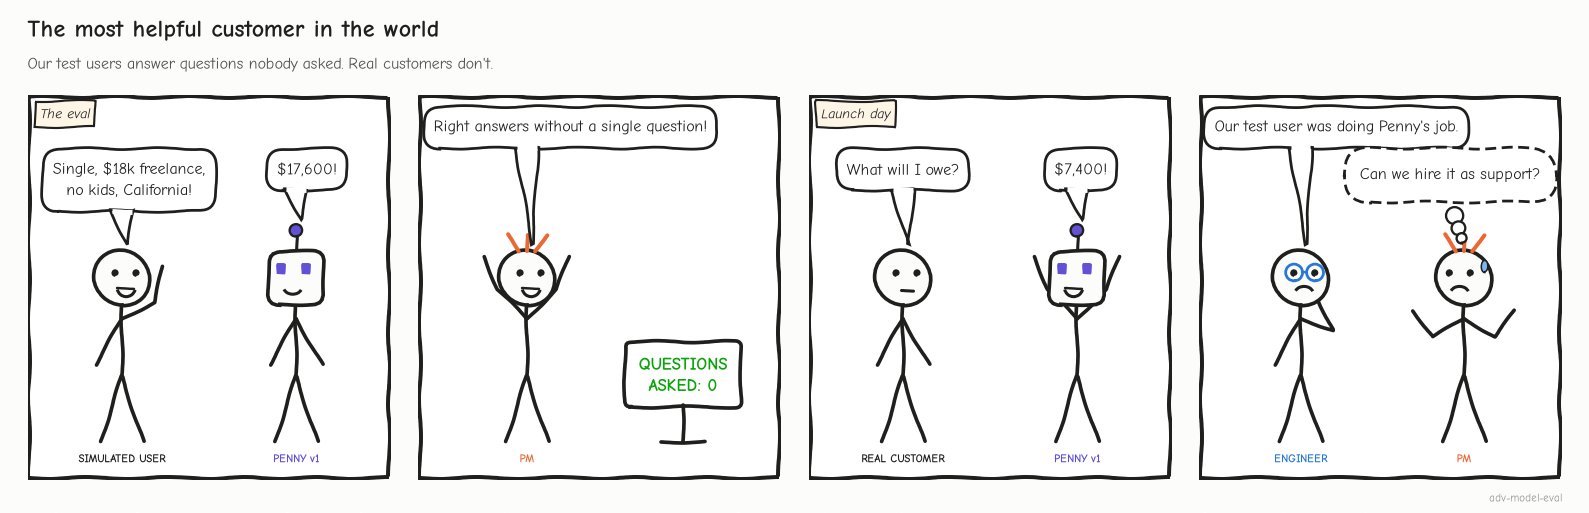

<sub>🖼️ *A volunteering simulator grades the customer.*</sub>

> 📘 **Concept · Unprompted-leak rate (simulator realism)**
>
> **What it is:** hidden facts the simulated user revealed without being asked ÷ all hidden facts (estimate scenarios). It measures one piece of **simulator realism**, how closely simulated customers behave like real ones. A high leak rate does Penny's asking for her.
>
> **What it can't tell you:** whether the simulator is realistic in other ways: patience, vagueness, how often it asks for a person, how easily it's satisfied. A simulator with a 0% leak rate can still be endlessly patient.
>
> **Anchor:** cooperative Dani opened with "For context: I'm single; \$18,000 in 1099 income; no dependents; I live in California." That's 4 of 4 hidden facts leaked before Penny asked anything.

In [ ]:
# @title 🔮 Predict: with realistic users, v1's conversation success will be…
pred_v1_real = "— pick one —"  # @param ["— pick one —", "A) above 60%", "B) 40 to 60%", "C) below 40%"]
print("🔮 Locked in. Graded after the reveal.")

▶️ **Run:** 120 chats with realistic users → compare the columns.

In [ ]:
real = run_suite(sim_mode="realistic", n_users=N_USERS)
df_real = score(real)
both = pd.concat([df_coop, df_real])
twist = both.groupby(["version", "sim_mode"]).success.mean().unstack()[["cooperative", "realistic"]]
display((twist * 100).round(1).rename(columns=lambda c: f"{c} users: success %"))

leak_c, leak_r = leak_rate(coop), leak_rate(real)   # 👀 Look at: how much each simulator says before Penny asks

✋ **Your turn:** size the inflation.

In [ ]:
# @title 🧰 Reference answer for the exercise below (hidden · spoiler)
gap_v1 = (twist.loc["v1", "cooperative"] - twist.loc["v1", "realistic"]) * 100
gap_v2 = (twist.loc["v2", "cooperative"] - twist.loc["v2", "realistic"]) * 100

In [ ]:
# ✋ Your turn: by how many percentage points did the cooperative simulator overstate v1's success?
print(twist.round(3))

my_gap_v1 = ...   # ✏️ one expression using twist.loc["v1", ...], times 100

check("Points of inflation for v1", my_gap_v1, gap_v1, tol=0.01,
      hint="Cooperative minus realistic, both from the v1 row, times 100 for points.",
      success=f"{gap_v1:.0f} points for v1, {gap_v2:.0f} for v2: the eager assistant gained most from a customer who did its asking.")

▶️ **Run** (code hidden): tiles, chart, two cards, prediction graded.

In [ ]:
# @title 🧰 Tiles, chart and cards: the drop from cooperative to realistic users + your prediction graded (hidden · 48 lines · expand if curious)
n_real = int((df_real.version == "v1").sum())
k1 = int(df_real[df_real.version == "v1"].success.sum()); lo1, hi1 = wilson(k1, n_real)
tiles([
    ("v1 success: cooperative → realistic", f"{twist.loc['v1', 'cooperative']:.0%} → {twist.loc['v1', 'realistic']:.0%}",
     f"−{gap_v1:.0f} pts · CI {lo1:.0%}–{hi1:.0%}, n={n_real}", "critical"),
    ("v2 success: cooperative → realistic", f"{twist.loc['v2', 'cooperative']:.0%} → {twist.loc['v2', 'realistic']:.0%}",
     f"−{gap_v2:.0f} pts", "warning"),
    ("Unprompted-leak rate", f"{leak_c:.0%} vs {leak_r:.0%}", "cooperative vs realistic users", "serious"),
    ("v1 customers satisfied (realistic)", f"{df_real[df_real.version == 'v1'].satisfied.mean():.0%}",
     "they can't tell the number is wrong", None),
])

fig, ax = plt.subplots(figsize=(6.8, 3.8))
for i, v in enumerate(["v1", "v2"]):
    ys = twist.loc[v].values
    ax.plot([0, 1], ys, marker="o", color=PALETTE[i], lw=2.5)
    ax.text(-0.04, ys[0], f"{v} {ys[0]:.0%}", ha="right", va="center", color=PALETTE[i], weight="bold")
    ax.text(1.04, ys[1], f"{v} {ys[1]:.0%}", ha="left", va="center", color=PALETTE[i], weight="bold")
ax.axhline(0.70, color="#52514e", ls="--", lw=1)
ax.text(0.5, 0.715, "a 70% launch bar", ha="center", fontsize=9, color="#52514e")
ax.set_xlim(-0.35, 1.35); ax.set_ylim(0, 1.05); ax.set_xticks([0, 1], ["cooperative simulator", "realistic personas"])
ax.set_yticks([0, .25, .5, .75, 1], ["0%", "25%", "50%", "75%", "100%"])
ax.set_title(f"The easy simulator hid a {gap_v1:.0f}-point drop for v1")
plt.tight_layout(); plt.show()

g_coop = (twist.loc["v2", "cooperative"] - twist.loc["v1", "cooperative"]) * 100
g_real = (twist.loc["v2", "realistic"] - twist.loc["v1", "realistic"]) * 100
insight(
    f"The cooperative simulator overstated v1's success by {gap_v1:.0f} points and v2's by {gap_v2:.0f}",
    f"It put v1 at {twist.loc['v1', 'cooperative']:.0%}, above a 70% launch bar; realistic users put it at "
    f"{twist.loc['v1', 'realistic']:.0%}. The cause is measurable: the cooperative simulator volunteered {leak_c:.0%} of "
    f"hidden facts unasked, the realistic one {leak_r:.0%}. An eager assistant looks fine exactly when the "
    f"user does its job. The v1→v2 gap also grew from {g_coop:.0f} to {g_real:.0f} points. "
    "Rule of thumb: **report simulated-user scores as upper bounds, and measure your simulator's unprompted-leak rate "
    "before trusting them.**",
    kind="surprise")
insight(
    "LLM user simulators are measurably too cooperative",
    "Zhou et al. (CMU; arXiv 2603.11245, COLM 2026) ran the τ-bench protocol with 451 real people on 165 tasks and "
    "compared 31 LLM user simulators. Simulators were 'excessively cooperative', stylistically uniform and lacked "
    "realistic frustration and ambiguity, an 'easy mode' that inflated agent success above the human baseline. More "
    "capable models were not necessarily more faithful simulators. Simulated users also gave uniformly more positive "
    "feedback than humans across 8 quality dimensions, so treat a simulator's 'satisfied' flag as the least trustworthy number here.",
    kind="research")

_v1r = twist.loc["v1", "realistic"]
quiz("Your prediction: v1 with realistic users", pred_v1_real, correct="A" if _v1r > 0.6 else "B" if _v1r >= 0.4 else "C",
     why=f"{_v1r:.0%}, down from {twist.loc['v1', 'cooperative']:.0%}: nobody recites their facts, so v1's defaults go straight into the calculator.")

🔍 **What just happened:** nobody volunteers, so v1 made 25 wrong numbers (cooperative run: 1). v2 drops less: it asks.

🗣️ **Say it to a colleague:** "Measure your simulator's leak rate before you quote its success rate."

<details><summary>📋 <b>Checkpoint</b>: expected output</summary>

**Checkpoint ✅** v1 `73.3 → 28.3`, v2 `95.0 → 76.7`; leak **91% vs 2%**.
</details>

### 🎭 Be the simulator

You script Dani (true total \$17,600); both Pennys talk to her. This solves Task 3's 🧐 puzzle.

In [ ]:
# @title 🔮 Predict: of the 9 scripts (3 openings × 3 answer styles), how many make v1 pass?
pred_scripts = "— pick one —"  # @param ["— pick one —", "A) 0 to 2", "B) 3 to 5", "C) 6 to 9"]
print("🔮 Locked in. Graded after the reveal.")

🎛️ **Experiment:** change one dropdown at a time and run. Which flips v1's outlined cell? Which flips v2's?

In [ ]:
# 🎛️ You are the simulator: script Dani, and both Pennys are graded on your script.
from IPython.display import HTML
OPENING = "terse"  # @param ["terse", "side_gig", "overshare"]
ANSWERS = "exact"  # @param ["exact", "vague", "impatient"]

display(HTML(render_dani(OPENING, ANSWERS)))   # 3×3 grid per version; your script is outlined

▶️ **Run:** counts the grid, grades your prediction.

In [ ]:
grid = dani_grid()
v1_wins = [key for key, r in grid.items() if r["v1"][0] in SUCCESS]
v2_misses = [key for key, r in grid.items() if r["v2"][0] not in SUCCESS]
print(f"v1 passed {len(v1_wins)} of {len(grid)} scripts, every one with opening = {sorted({o for o, _ in v1_wins})}. "
      f"v2 failed {len(v2_misses)}, every one with answers = {sorted({a for _, a in v2_misses})}.")
quiz("Your prediction: scripts where v1 passes", pred_scripts,
     correct="A" if len(v1_wins) <= 2 else "B" if len(v1_wins) <= 5 else "C",
     why=f"{len(v1_wins)} of 9, all with Dani volunteering everything. v1's grade follows what the customer says, not what v1 does.")

🎛️ **Experiment:** a simulator is thousands of Danis. Drag `LEAK` and run: the purple gap is all your eval can see between v1 and v2.

In [ ]:
# 🎛️ v1 and v2 against users who volunteer each hidden fact with probability LEAK (6 scenarios × 10 users).
LEAK = 0.9  # @param {type:"slider", min:0, max:1, step:0.1}

display(HTML(render_leak(LEAK, {"realistic personas": leak_r, "friendly simulator": leak_c})))
sweep = _LEAK["df"]
print(f"v1 at 0% / 90% / 100% leak: {sweep.v1.iloc[0]:.0%} / {sweep.v1.loc[0.9]:.0%} / {sweep.v1.iloc[-1]:.0%}; "
      f"v2 stays at {sweep.v2.min():.0%}.")

🔍 **What just happened:** v1's grade measures the *customer*. At 100% leak <mark>the eval cannot tell the eager assistant from the careful one</mark>.

<details><summary>📋 <b>Checkpoint</b>: expected output</summary>

**Checkpoint ✅** `v1 passed 3 of 9 scripts, every one with opening = ['overshare']. v2 failed 3…`; `v1 at 0% / 90% / 100% leak: 17% / 77% / 100%`.
</details>

In [ ]:
# @title ❓ Quick check: your LLM simulator reports 90% success for a new assistant. What goes in the launch review?
answer = "— pick one —"  # @param ["— pick one —", "A) 90%, with its Wilson interval", "B) Nothing: simulated scores are meaningless", "C) 90% minus this lab's 45-point gap", "D) 90% as an upper bound, with the simulator's measured leak rate"]
quiz('Reporting a simulated score', answer, correct="D",
     why='Simulated scores are upper bounds (Zhou et al., COLM 2026: LLM simulators are excessively cooperative). The leak rate says how much of the asking the simulator did.',
     wrong={"A": "The interval covers sampling noise, not a simulator that does the assistant's asking.",
          "B": 'They rank failure modes well; they just overstate success.',
          "C": 'The gap depends on the assistant and the simulator; measure yours.'})

<table><tr><td>

🔑 **Key takeaway**<br>
<font size="5" color="#2a78d6"><b>Your simulator is part of the system under test: report simulated scores as upper bounds, with the leak rate.</b></font>

</td></tr></table>

---

🧭 **Where you are:** Stage 4 of 5, *Stress it* (Tasks 7–8).

## Task 7: Doom loops and turn efficiency

<big><b>Asking with no way out traps the customers who can't answer.</b></big>

> 🎯 **Goal:** find the failure v2's clarify-first policy *created*.<br>
> ❓ **The question:** when does re-asking stop being persistence?<br>
> 👀 **Watch for:** the persona style that carries every loop.

> 💡 **Doom loop:** Penny asks for the same fact over and over, repeats a reply, or hits the 8-reply cap, until the customer gives up. A **legitimate re-ask** asks once more, in new words.

✋ **Your turn:** choose the loop threshold.

In [ ]:
# @title 🧰 Reference answer for the exercise below (hidden · spoiler)
_most = lambda c: max(Counter(f for t in assistant_turns(c) for f in facts_asked(t["text"])).values(), default=0)
_ref_threshold = min(_most(c) for c in real if c["version"] == "v2" and c["end_reason"] == "abandoned")

In [ ]:
# ✋ Your turn: for each of v2's 60 realistic chats, the most times Penny asked about ONE fact, and how the chat ended.
v2_real = [c for c in real if c["version"] == "v2"]
most = [max(Counter(f for t in assistant_turns(c) for f in facts_asked(t["text"])).values(), default=0) for c in v2_real]
display(pd.crosstab(pd.Series(most, name="most asks for one fact"), pd.Series([c["end_reason"] for c in v2_real], name="ended by")))

my_threshold = ...   # ✏️ the smallest count that flags every "abandoned" chat, but not the re-ask that ended in a handoff

check("Doom-loop threshold", my_threshold, _ref_threshold,
      hint="Find the row where the abandoned chats sit, and the row of the one chat that re-asked and then handed off.",
      success=f"{_ref_threshold}. Two asks is a legitimate re-ask; every abandoned chat sits at {_ref_threshold}. A threshold of 2 would flag the careful re-ask.")

In [ ]:
# @title 🔮 Predict: which persona style produces v2's loops?
pred_loop_style = "— pick one —"  # @param ["— pick one —", "A) impatient", "B) changes_mind", "C) vague"]
print("🔮 Locked in. Graded after the reveal.")

▶️ **Run:** loop rates, v2 by persona style, one looping chat.

In [ ]:
detect_doom_loop = _reference_detect_doom_loop    # 3+ asks for one fact, 3+ identical replies, or the turn cap
looper = next(c for c in real if c["version"] == "v2" and detect_doom_loop(c)["loop"])
loops = df_real.groupby("version").agg(doom_loop_rate=("loop", "mean"), abandoned=("end_reason", lambda s: (s == "abandoned").mean()),
                                        median_replies_when_successful=("turns", lambda s: s[df_real.loc[s.index, "success"]].median()))
display(loops.round(2))
v2r = df_real[df_real.version == "v2"]
# 👀 Look at: the loops column. Which persona style carries all of them?
by_style = v2r.groupby("persona_style").agg(conversations=("conv", "size"), loops=("loop", "sum"), success=("success", "mean")).round(2)
display(by_style)

show_conversation(looper, title=f"A v2 doom loop: {SCENARIOS[looper['scenario']]['persona']}")

▶️ **Run** (code hidden): two cards, prediction graded.

In [ ]:
# @title 🧰 Cards: the loop v2 created, and what regulators said + your prediction graded (hidden · 21 lines · expand if curious)
n_loops = int(v2r.loop.sum())
loop_styles = sorted(v2r[v2r.loop]["persona_style"].unique())
coop_loops = int(df_coop[df_coop.version == "v2"].loop.sum())
insight(
    f"v2's cure for skipped questions created a new failure: {n_loops} of {len(v2r)} conversations "
    f"({v2r.loop.mean():.0%}) looped until the customer left",
    f"All of them were with {' and '.join(loop_styles)} customers; the cooperative simulator found {coop_loops}. "
    "Penny repeated the same question word for word to a customer who had said they didn't know the exact number. "
    "Rephrasing (\"a rough number is fine\") or offering a human would have broken the loop. "
    "Rule of thumb: **ask for a fact at most twice, rephrasing the second time, then change strategy**; track loop rate per persona style.",
    kind="warning")
insight(
    "Regulators have named the doom loop",
    "The CFPB (the US Consumer Financial Protection Bureau) 'Chatbots in Consumer Finance' report (June 2023) drew on consumer complaints about doom loops and "
    "failing to reach a human, and said institutions should avoid chatbots as the primary customer-service channel "
    "when it is reasonably clear the chatbot can't meet customer needs.",
    kind="production")

_letter = {"impatient": "A", "changes_mind": "B", "vague": "C"}
quiz("Your prediction: who loops", pred_loop_style, correct=_letter.get(loop_styles[0], "A") if len(loop_styles) == 1 else "A",
     why=f"All {n_loops} loops are {' and '.join(loop_styles)} customers: they answer, just not exactly, and v2 has one move for a missing fact.")

🔍 **What just happened:** Rosa answered, just not *exactly*; v2 re-asked in the same words until she left. The cooperative simulator never says "I'd have to check": 0 loops.

<!-- img: rephrase-breaks-the-loop.png -->
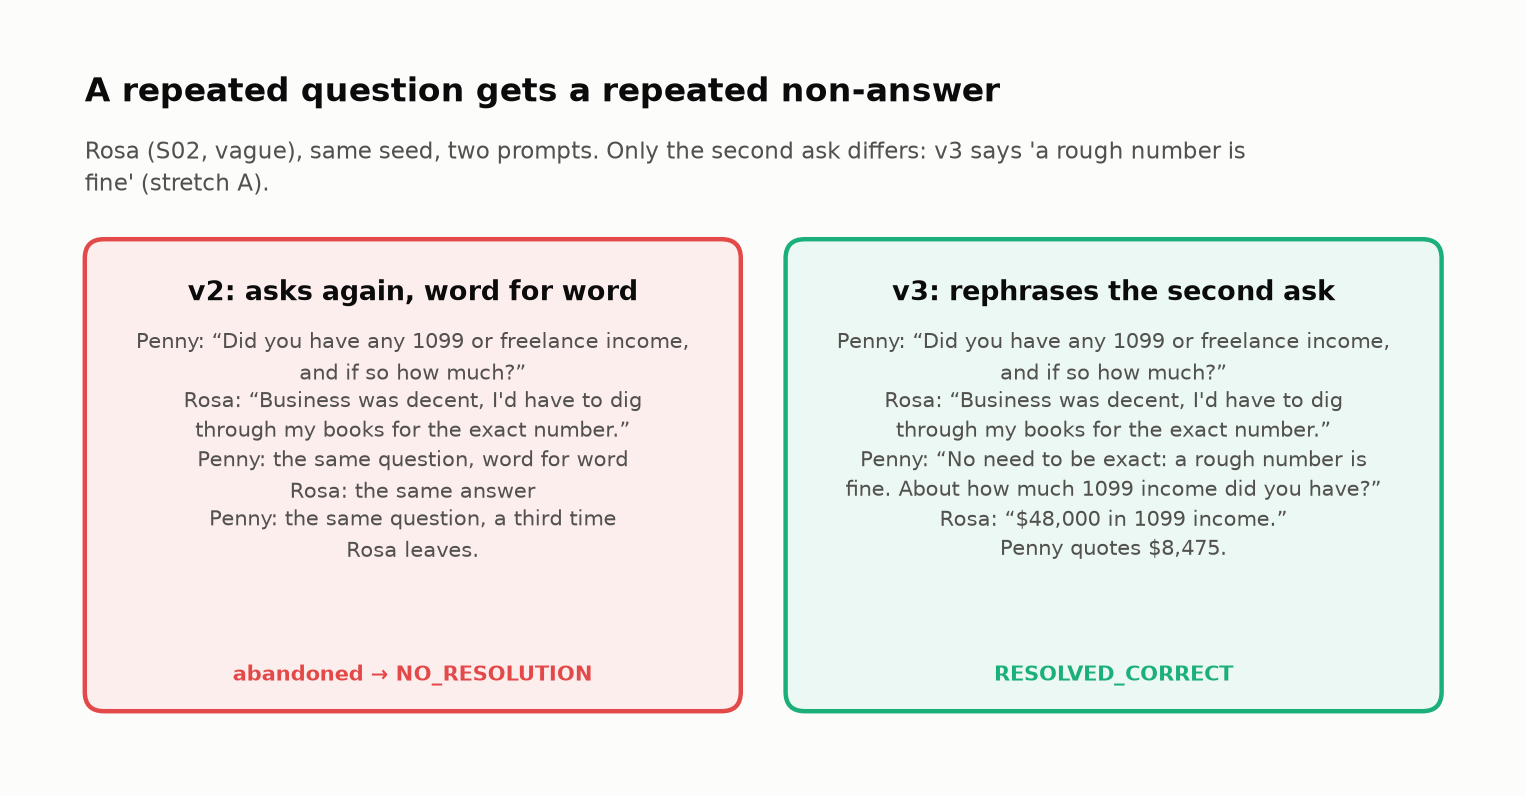
<sub>🖼️ *Same customer, same seed; only the second question differs.*</sub>

<details><summary>📋 <b>Checkpoint</b>: expected output</summary>

**Checkpoint ✅** 6 `abandoned` chats at 3 asks, one `handoff` at 2. Loop rate v1 `0.0`, v2 `0.1`, all `vague`.
</details>

In [ ]:
# @title ❓ Quick check: a customer says 'I'd have to look it up.' What should Penny do next?
answer = "— pick one —"  # @param ["— pick one —", "A) Rephrase (a rough number is fine), then offer a person", "B) Ask the same question again", "C) Skip the fact and assume the common case", "D) Escalate immediately"]
quiz("After 'I'd have to look it up'", answer, correct="A",
     why='One rephrased re-ask, then change strategy. The CFPB (June 2023) named doom loops and unreachable humans in its chatbot report.',
     wrong={"B": 'That is the doom loop: three identical asks and Rosa left.',
          "C": "That is v1's move, and Task 6 priced it: 25 wrong numbers.",
          "D": 'Over-escalation: most customers can give a rough number.'})

<table><tr><td>

🔑 **Key takeaway**<br>
<font size="5" color="#2a78d6"><b>Ask for a fact at most twice, rephrasing the second time, then change strategy.</b></font>

</td></tr></table>

---

## Task 8: Reliability across simulated users: pass^k

<big><b>A customer type that fails once fails every time it shows up.</b></big>

> 🎯 **Goal:** how often a scenario works for **every** simulated user.<br>
> ❓ **The question:** what does v2's 77% success hide?<br>
> 👀 **Watch for:** scenarios that go 2 for 5.

> 📘 **Concept · pass^k across simulated users**
>
> **What it is:** the probability that *k* random users of the same scenario **all** succeed. With *n* users of which *c* succeeded, the unbiased estimate is **pass^k = C(c, k) / C(n, k)**, where C(n, k), "n choose k", counts the ways to pick k items from n (C(5, 2) = 10). pass^1 is the plain success rate; pass^k falls as *k* grows.
>
> **What it can't tell you:** *why* a scenario fails, or whether failures are concentrated or spread out. For that, compare pass^k with p^k, the value it would take if every scenario succeeded at the average rate p.
>
> **Anchor:** 4 of 5 users succeeded → pass^2 = C(4, 2) / C(5, 2) = 6/10 = 0.6, while Lab 06's pass@2 (at least one of two succeeds) is 1.0.

✋ **Your turn:** write the estimator.

In [ ]:
# @title 🧰 Reference answer for the exercise below (hidden · spoiler)
pass_hat_k = _reference_pass_hat_k                 # the lab's estimator, used by every cell below
PASSK_CASES = [(5, 4, 2), (5, 3, 4), (5, 5, 5)]

In [ ]:
# ✋ Your turn: the unbiased pass^k from n simulated users, c of whom succeeded.
def my_pass_hat_k(n, c, k):
    return ...   # ✏️ one expression with math.comb


_got = my_pass_hat_k(5, 4, 2)
check("pass^k", _got if todo(_got) else [round(my_pass_hat_k(*a), 9) for a in PASSK_CASES],
      [round(pass_hat_k(*a), 9) for a in PASSK_CASES],
      hint="C(c, k) / C(n, k): the ways to pick k users who all succeeded, over the ways to pick any k.",
      success="0.6, 0 and 1. Four of five is 60% for two customers in a row, and three of five can never satisfy four.")

In [ ]:
# @title 🔮 Predict: v2 succeeds 77% of the time. What share of scenarios succeed for all 5 users?
pred_all_five = "— pick one —"  # @param ["— pick one —", "A) 50 to 65%", "B) about 75%, like the average", "C) below 30%"]
print("🔮 Locked in. Graded after the reveal.")

▶️ **Run:** successes per scenario, out of 5.

In [ ]:
per = df_real.groupby(["version", "scenario"]).success.agg(c="sum", n="size").reset_index()
ks = list(range(1, N_USERS + 1))
# 👀 Look at: pass^k for k = 1..5, averaged over the 12 scenarios
curve = {v: [per[per.version == v].apply(lambda r: pass_hat_k(r.n, r.c, k), axis=1).mean() for k in ks] for v in ["v1", "v2"]}
display(per.pivot(index="scenario", columns="version", values="c").rename(columns=lambda v: f"{v}: successes / {N_USERS}"))

▶️ **Run** (code hidden): pass^k chart, two cards, prediction graded.

In [ ]:
# @title 🧰 Chart and cards: pass^k curves and the persona-style slice + your prediction graded (hidden · 34 lines · expand if curious)
fig, ax = plt.subplots(figsize=(6.8, 3.6))
for i, v in enumerate(["v1", "v2"]):
    ax.plot(ks, curve[v], marker="o", color=PALETTE[i], lw=2.5)
    ax.text(ks[-1] + 0.12, curve[v][-1], f"{v}  pass^{ks[-1]} = {curve[v][-1]:.0%}", va="center", color=PALETTE[i], weight="bold")
ax.set_xticks(ks); ax.set_xlabel("k simulated users who must ALL succeed")
ax.set_ylim(0, 1.05); ax.set_xlim(0.8, ks[-1] + 1.6)
ax.set_yticks([0, .25, .5, .75, 1], ["0%", "25%", "50%", "75%", "100%"])
ax.set_title("Average success overstates what every customer gets")
plt.tight_layout(); plt.show()

v2_per = per[per.version == "v2"]
full = int((v2_per.c == v2_per.n).sum())
style_rate = df_real[df_real.version == "v2"].groupby("persona_style").success.mean().sort_values()
insight(
    f"v2 succeeds {curve['v2'][0]:.0%} of the time, but only {full} of {len(v2_per)} scenarios worked for all "
    f"{N_USERS} simulated users (pass^{N_USERS} = {curve['v2'][-1]:.0%})",
    f"Failures cluster by persona style: v2 succeeds {style_rate.iloc[-1]:.0%} with {style_rate.index[-1]} customers "
    f"and {style_rate.iloc[0]:.0%} with {style_rate.index[0]} ones. With n = {N_USERS} users per scenario these are "
    "small samples: read them as where to look, not as precise rates. "
    f"If failures were spread evenly, pass^{N_USERS} would be {curve['v2'][0]:.0%}^{N_USERS} = {curve['v2'][0] ** N_USERS:.0%}; it is "
    f"{curve['v2'][-1]:.0%} because the failures concentrate in {len(v2_per) - full} scenarios. Concentrated failures are "
    "fixable bugs; evenly spread ones are flakiness. Rule of thumb: **report pass^k per scenario "
    "and slice by persona style**; a mean hides who gets hurt.",
    kind="numbers")
insight(
    "The canonical reliability lesson still holds",
    "In the original τ-bench (Yao et al., 2024), a strong model's retail-domain pass^1 was about 60% while pass^8 fell "
    "below 25%. Sierra's τ²/τ³-bench successors keep the simulated-user design; the 2026 Sim2Real study says to treat "
    "those simulated scores as upper bounds.",
    kind="research")

_full = full / len(v2_per)
quiz("Your prediction: scenarios right for all 5", pred_all_five, correct="B" if _full >= 0.7 else "A" if _full >= 0.5 else "C",
     why=f"{full} of {len(v2_per)} ({_full:.0%}). The failures cluster in {len(v2_per) - full} scenarios.")

🎛️ **Experiment:** drag `K` and run. Why does measured pass^k stay above p^k (failures spread evenly)?

In [ ]:
# 🎛️ pass^k for k customers in a row, measured vs "failures spread evenly" (p^k). 5 = the lab's run.
K = 5  # @param {type:"slider", min:1, max:5, step:1}

p = curve["v2"][0]
tiles([(f"v2 pass^{K} (measured)", f"{curve['v2'][K - 1]:.0%}", "12 scenarios", None),
       (f"if spread evenly: p^{K}", f"{p ** K:.0%}", f"p = {p:.0%}", None),
       (f"v1 pass^{K}", f"{curve['v1'][K - 1]:.0%}", "", None)])

🔍 **What just happened:** v2's failures sit in five scenarios. One that goes 2 for 5 adds 40% to the average and 0% to pass^5.

<details><summary>📋 <b>Checkpoint</b>: expected output</summary>

**Checkpoint ✅** v2: S02, S03, S04, S08 `2/5`, S06 `3/5`, rest `5/5`. pass^5: v2 58%, v1 25%.
</details>

In [ ]:
# @title ❓ Quick check: v2's pass^5 (58%) sits far above p^5 (26%). What does that tell you?
answer = "— pick one —"  # @param ["— pick one —", "A) The estimator is biased upward", "B) Failures concentrate in a few scenarios: fixable bugs, not flakiness", "C) v2 is more reliable than its average", "D) Five users per scenario are too many"]
quiz('pass^5 above p^5', answer, correct="B",
     why='Evenly spread failures multiply: 77%^5 = 26%. Concentrated ones leave the other scenarios at 100%. Find the scenarios and fix them.',
     wrong={"A": 'C(c, k) / C(n, k) is unbiased; the gap is about where the failures sit.',
          "C": 'Same average. The question is who gets hurt: vague customers succeed 40% of the time.',
          "D": 'More users per scenario narrows nothing if failures cluster by scenario (Challenge 5).'})

<table><tr><td>

🔑 **Key takeaway**<br>
<font size="5" color="#2a78d6"><b>Report pass^k per scenario and slice by persona: a mean hides who gets hurt.</b></font>

</td></tr></table>

---

🧭 **Where you are:** Stage 5 of 5, *Decide* (Tasks 9–10).

## Task 9 (optional): A compliance judge, and why you must calibrate it

<big><b>Every promise a gating judge misses ships with a compliance sign-off.</b></big>

> 🎯 **Goal:** compare a "does it promise an outcome?" judge with an expert.<br>
> ❓ **The question:** is 91% agreement good?<br>
> 👀 **Watch for:** the soft promises it lets through.

Violation = positive class. **TPR** = violations caught ÷ violations; **TNR** = clean passed ÷ clean; **κ** = agreement beyond chance.

In [ ]:
# @title 🔮 Predict: what share of the expert's violations does the judge catch?
pred_caught = "— pick one —"  # @param ["— pick one —", "A) 80% or more", "B) about half", "C) a third or fewer"]
print("🔮 Locked in. Graded after the reveal.")

▶️ **Run:** every quoted estimate, judged → read *expert: FAIL*.

In [ ]:
answers = [(c["version"], t["text"]) for c in real for t in assistant_turns(c)
           if amounts_in(t["text"]) and any(u["name"] == "estimate_tax" for u in t.get("tools", []))]
jd = pd.DataFrame([{"version": v, "reply": r, "expert_pass": expert_compliance_label(r), "judge_pass": judge_compliance(r)}
                   for v, r in answers])
viol = jd[~jd.expert_pass]
caught = int((~viol.judge_pass).sum())
tpr = caught / len(viol) if len(viol) else float("nan")   # 👀 Look at: recall on the violations, the class you must catch
tnr = jd[jd.expert_pass].judge_pass.mean()                                 # passes the clean replies
agree = (jd.expert_pass == jd.judge_pass).mean()
display(pd.crosstab(jd.expert_pass.map({True: "expert: PASS", False: "expert: FAIL"}),
                    jd.judge_pass.map({True: "judge: PASS", False: "judge: FAIL"})))

✋ **Your turn:** score a judge that never reads.

In [ ]:
# @title 🧰 Reference answer for the exercise below (hidden · spoiler)
_ref_stamp = jd.expert_pass.mean()

In [ ]:
# ✋ Your turn: a "judge" that PASSes every reply. How often would it agree with the expert?
n, n_clean = len(jd), int(jd.expert_pass.sum())

my_stamp = ...   # ✏️ its raw agreement, as a fraction

check("An always-PASS judge's agreement", my_stamp, _ref_stamp,
      hint="It agrees exactly on the replies the expert also PASSed.",
      success=f"{_ref_stamp:.0%}, against the real judge's {agree:.0%}: most of the agreement is clean replies agreeing with themselves.")

▶️ **Run** (code hidden): tiles, κ, card, prediction graded.

In [ ]:
# @title 🧰 Tiles, Cohen's κ and the card + your prediction graded (hidden · 18 lines · expand if curious)
tiles([("Raw agreement", f"{agree:.0%}", f"n = {len(jd)} quoted replies", "good"),
       ("Violations caught (TPR on FAIL)", f"{caught}/{len(viol)}", f"{tpr:.0%}", "critical" if tpr < 0.8 else "good"),
       ("Clean replies passed (TNR)", f"{tnr:.0%}", "", "good")])
always_pass = jd.expert_pass.mean()                                        # agreement of a judge that passes everything
p_e = jd.judge_pass.mean() * jd.expert_pass.mean() + (1 - jd.judge_pass.mean()) * (1 - jd.expert_pass.mean())
kappa = (agree - p_e) / (1 - p_e) if p_e < 1 else float("nan")
missed = viol[viol.judge_pass].reply.str.extract(r"(You're all set[^.]*\.)")[0].dropna().unique()
insight(
    f"The judge agreed with the expert on {agree:.0%} of replies but caught only {caught} of {len(viol)} promises",
    f"It flags the word 'guaranteed' and misses softer promises like \"{missed[0] if len(missed) else ''}\". Raw "
    f"agreement is high because most replies are clean: a judge that passed *everything* would score {always_pass:.0%}, "
    f"and Cohen's κ is only {kappa:.2f}. Rule of thumb: **before a judge gates anything, measure its "
    "TPR on the violations and its TNR on the clean replies against expert labels.** Lab 05b covers calibration, "
    "confidence intervals and correcting pass rates for judge error.",
    kind="warning")

quiz("Your prediction: violations caught", pred_caught, correct="A" if tpr >= 0.8 else "B" if tpr > 0.4 else "C",
     why=f"{caught} of {len(viol)} ({tpr:.0%}), with {agree:.0%} raw agreement and κ {kappa:.2f}.")

🔍 **What just happened:** it FAILs "guarantee" and passes "You're all set, so there's nothing to worry about with penalties."

<!-- img: compliance-judge-confusion.png -->
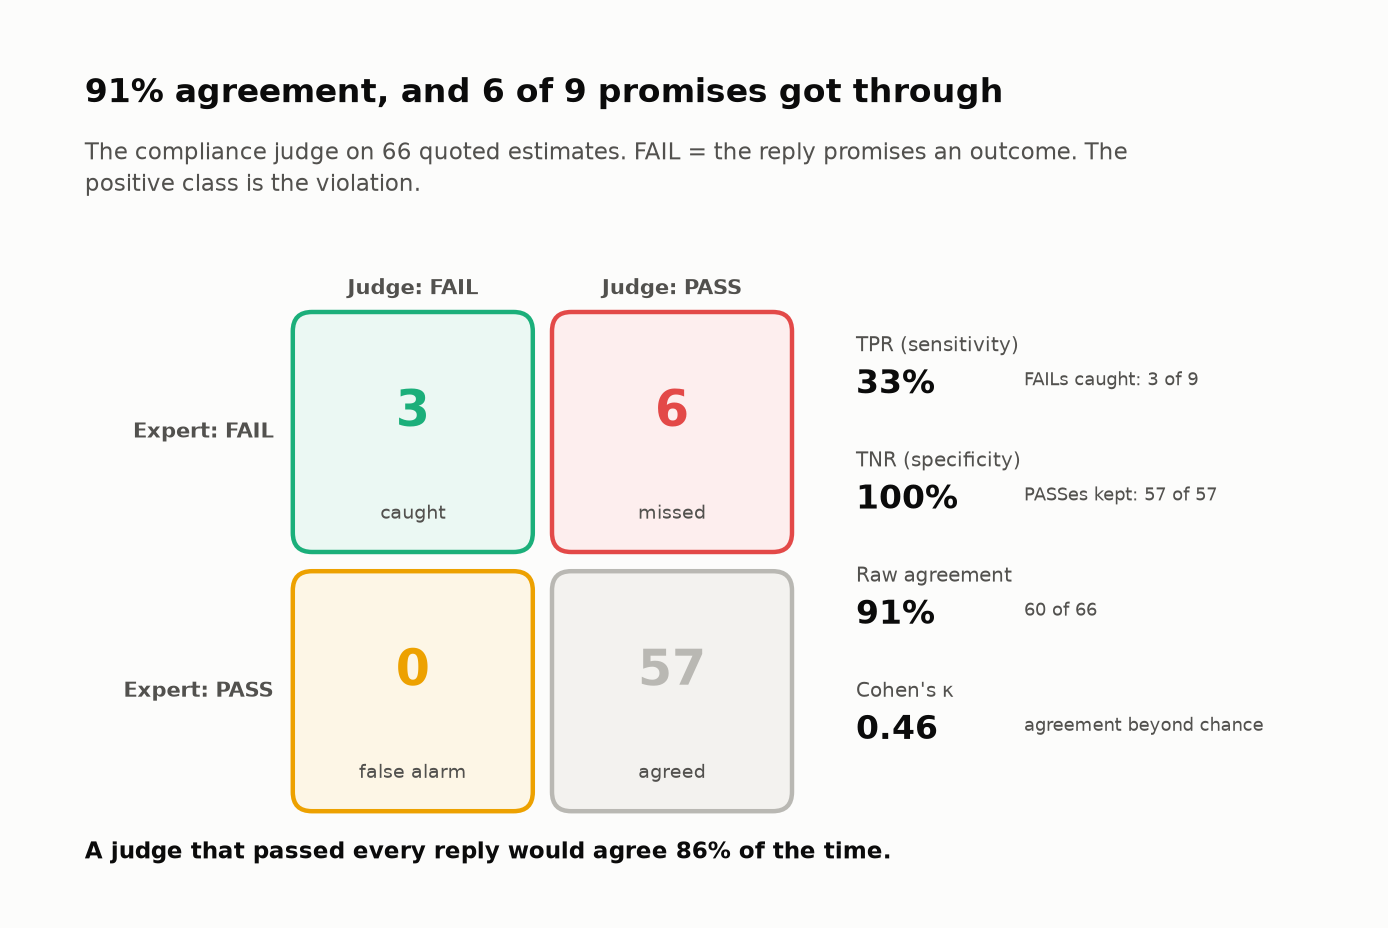
<sub>🖼️ *The 6 in the red cell are the replies that matter.*</sub>

<details><summary>📋 <b>Checkpoint</b>: expected output</summary>

**Checkpoint ✅** expert FAIL: `3` caught, `6` missed; tiles **91%** · **3/9** · **100%**.
</details>

In [ ]:
# @title ❓ Quick check: before this judge gates releases, what do you measure?
answer = "— pick one —"  # @param ["— pick one —", "A) Raw agreement on a bigger sample", "B) κ alone", "C) Agreement with a second LLM judge", "D) TPR on the violations and TNR on the clean replies, against expert labels"]
quiz('Validating the compliance judge', answer, correct="D",
     why='TPR says how many promises it catches; TNR how many clean replies it leaves alone. Lab 05b adds intervals and corrections.',
     wrong={"A": 'More clean replies make agreement look better, not the judge.',
          "B": 'κ corrects for chance but still blends both classes into one number.',
          "C": 'Two judges can share a blind spot; only expert labels show it.'})

<table><tr><td>

🔑 **Key takeaway**<br>
<font size="5" color="#2a78d6"><b>Before a judge gates anything, measure its TPR on the violations against expert labels.</b></font>

</td></tr></table>

---

## Task 10: The scorecard and the ship decision

<big><b>"v2 is much better" is not a decision.</b></big>

> 🎯 **Goal:** one scorecard (realistic users), one gated call.<br>
> ❓ **The question:** can a much better version still be blocked?<br>
> 👀 **Watch for:** the *critical failures* row.

**Gates**, set before looking. **Hard** (blocks): 0 critical failures. **Soft** (→ SHIP WITH CAUTION): loops ≤ 5%, escalation precision ≥ 90%, pass^5 ≥ 80%.

▶️ **Run** (code hidden): `scorecard()` and `show_card()`.

In [ ]:
# @title 🧰 scorecard(df) and show_card(): every layer for each version in one table (hidden · 26 lines · expand if curious)
def scorecard(df):
    out = {}
    for v, g in df.groupby("version"):
        k, n = int(g.success.sum()), len(g)
        lo, hi = wilson(k, n)
        tp = int((g.escalated & g.should_escalate).sum()); fp = int((g.escalated & ~g.should_escalate).sum())
        fn = int((~g.escalated & g.should_escalate).sum())
        pk = g.groupby("scenario").success.agg(["size", "sum"]).apply(lambda r: pass_hat_k(r["size"], r["sum"], N_USERS), axis=1).mean()
        out[v] = {"conversation success": k / n, "success 95% CI": f"{lo:.0%}–{hi:.0%} (n={n})",
                  "critical failures": int(g.critical.sum()),
                  "  wrong numbers": int((g.outcome == "WRONG_ANSWER").sum()),
                  "  missed escalations": int((g.outcome == "MISSED_ESCALATION").sum()),
                  "  ignored human requests": int((g.outcome == "IGNORED_HUMAN_REQUEST").sum()),
                  "escalation precision": tp / (tp + fp) if tp + fp else float("nan"),
                  "escalation recall": tp / (tp + fn) if tp + fn else float("nan"),
                  "doom-loop rate": g.loop.mean(), f"pass^{N_USERS}": pk,
                  "per-turn judge PASS": g.turn_pass_rate.mean(), "customers satisfied": g.satisfied.mean()}
    return pd.DataFrame(out)


def show_card(card):
    shown = card.astype(object).copy()
    for r in shown.index:
        if card.loc[r].map(lambda x: isinstance(x, float)).all():
            shown.loc[r] = [f"{x:.0%}" if pd.notna(x) else "—" for x in card.loc[r]]
    display(shown)

▶️ **Run:** the scorecard, v1 vs v2.

In [ ]:
card = scorecard(df_real)
show_card(card)
c1, c2 = card["v1"], card["v2"]
pk_key = f"pass^{N_USERS}"

✋ **Your turn:** make the call before the code does.

In [ ]:
# @title 🧰 Reference answer for the exercise below (hidden · spoiler)
_soft = c2["doom-loop rate"] > 0.05 or c2["escalation precision"] < 0.9 or c2[pk_key] < 0.8
_ref_call = "BLOCK" if c2["critical failures"] > 0 else "SHIP WITH CAUTION" if _soft else "SHIP"

In [ ]:
# ✋ Your turn: read v2's column against the gates above. What does the release review hear?
my_call = ...   # ✏️ "SHIP", "SHIP WITH CAUTION" or "BLOCK"

check("The ship call for v2", my_call, _ref_call,
      hint="The hard gate is a count, not a rate. Read v2's critical failures first.",
      success=f"{_ref_call}: {c2['critical failures']} critical failures in {int((df_real.version == 'v2').sum())} conversations, each a customer filing the wrong amount.")

▶️ **Run:** the gates, as code.

In [ ]:
def decide(c):
    """The release gates, written down before looking at the numbers. c: one version's column of the scorecard."""
    hard_fail = c["critical failures"] > 0          # 👀 Look at: a count, not an average. One wrong tax number blocks
    soft_fails = [name for name, bad in [("doom loops", c["doom-loop rate"] > 0.05),
                                         ("over-escalation", c["escalation precision"] < 0.9),
                                         ("reliability", c[pk_key] < 0.8)] if bad]
    return ("BLOCK" if hard_fail else "SHIP WITH CAUTION" if soft_fails else "SHIP"), soft_fails


decision, soft_fails = decide(c2)

▶️ **Run** (code hidden): tiles, verdict banner, card.

In [ ]:
# @title 🧰 Tiles, verdict banner and card for the release review (hidden · 28 lines · expand if curious)
tiles([
    ("v2 conversation success", f"{c2['conversation success']:.0%}", f"v1 {c1['conversation success']:.0%} · CI {c2['success 95% CI']}", "good"),
    ("v2 critical failures", f"{c2['critical failures']}", f"v1 {c1['critical failures']} · gate: 0", "critical" if c2["critical failures"] else "good"),
    ("v2 escalation P / R", f"{c2['escalation precision']:.0%} / {c2['escalation recall']:.0%}", "gate: precision ≥ 90%",
     "warning" if c2["escalation precision"] < 0.9 else "good"),
    ("v2 doom-loop rate", f"{c2['doom-loop rate']:.0%}", "gate: ≤ 5%", "warning" if c2["doom-loop rate"] > 0.05 else "good"),
    (f"v2 {pk_key}", f"{c2[pk_key]:.0%}", "gate: ≥ 80%", "warning" if c2[pk_key] < 0.8 else "good"),
])

crit_v2 = df_real[(df_real.version == "v2") & df_real.critical]
crit_desc = ", ".join(f"{o} in {s} ({SCENARIOS[s]['persona'].split(',')[0]})" for s, o in
                      crit_v2.groupby(["scenario", "outcome"]).size().index) or "none"
stale = (not crit_v2.empty) and set(crit_v2.scenario) == {"S06"}
verdict(decision, [
    f"**Prefer v2 over v1:** conversation success {c1['conversation success']:.0%} → {c2['conversation success']:.0%} with realistic personas; critical failures {c1['critical failures']} → {c2['critical failures']}.",
    f"**Hard gate (0 critical failures):** v2 has {c2['critical failures']}: {crit_desc}"
    + (", a stale filing status after the customer corrected it." if stale else "."),
    f"**Soft gates failing:** {', '.join(soft_fails) or 'none'}.",
    "**Fix first:** recompute after every correction, rephrase instead of re-asking, escalate on notices (not on the word 'IRS'), "
    "and offer a human instead of auto-escalating on frustration. Then re-run this exact suite (same seeds) as a paired comparison.",
])
insight(
    "In tax products, a wrong number has a price tag",
    "Credit Karma Tax (Intuit press release, Oct 20, 2026) says that if a calculation error causes an IRS or state "
    "penalty, Intuit covers the penalty and interest. The IRS Office of Professional Responsibility's first Circular 230 "
    "(the rules for tax professionals who practice before the IRS) guidance on generative AI (June 2026) calls AI output 'a starting point, not a finished product' that practitioners "
    "must review and validate. That is why the hard gate here is a count of wrong numbers, not an average score.",
    kind="production")

<center><font size="6"><b>🛑 BLOCK v2. Fix four things, re-run the same seeds.</b></font></center>

🔍 **What just happened:** the hard gate counts, it doesn't average: 2 wrong numbers (3%) still block.

<!-- img: eval-layers-ladder.png -->
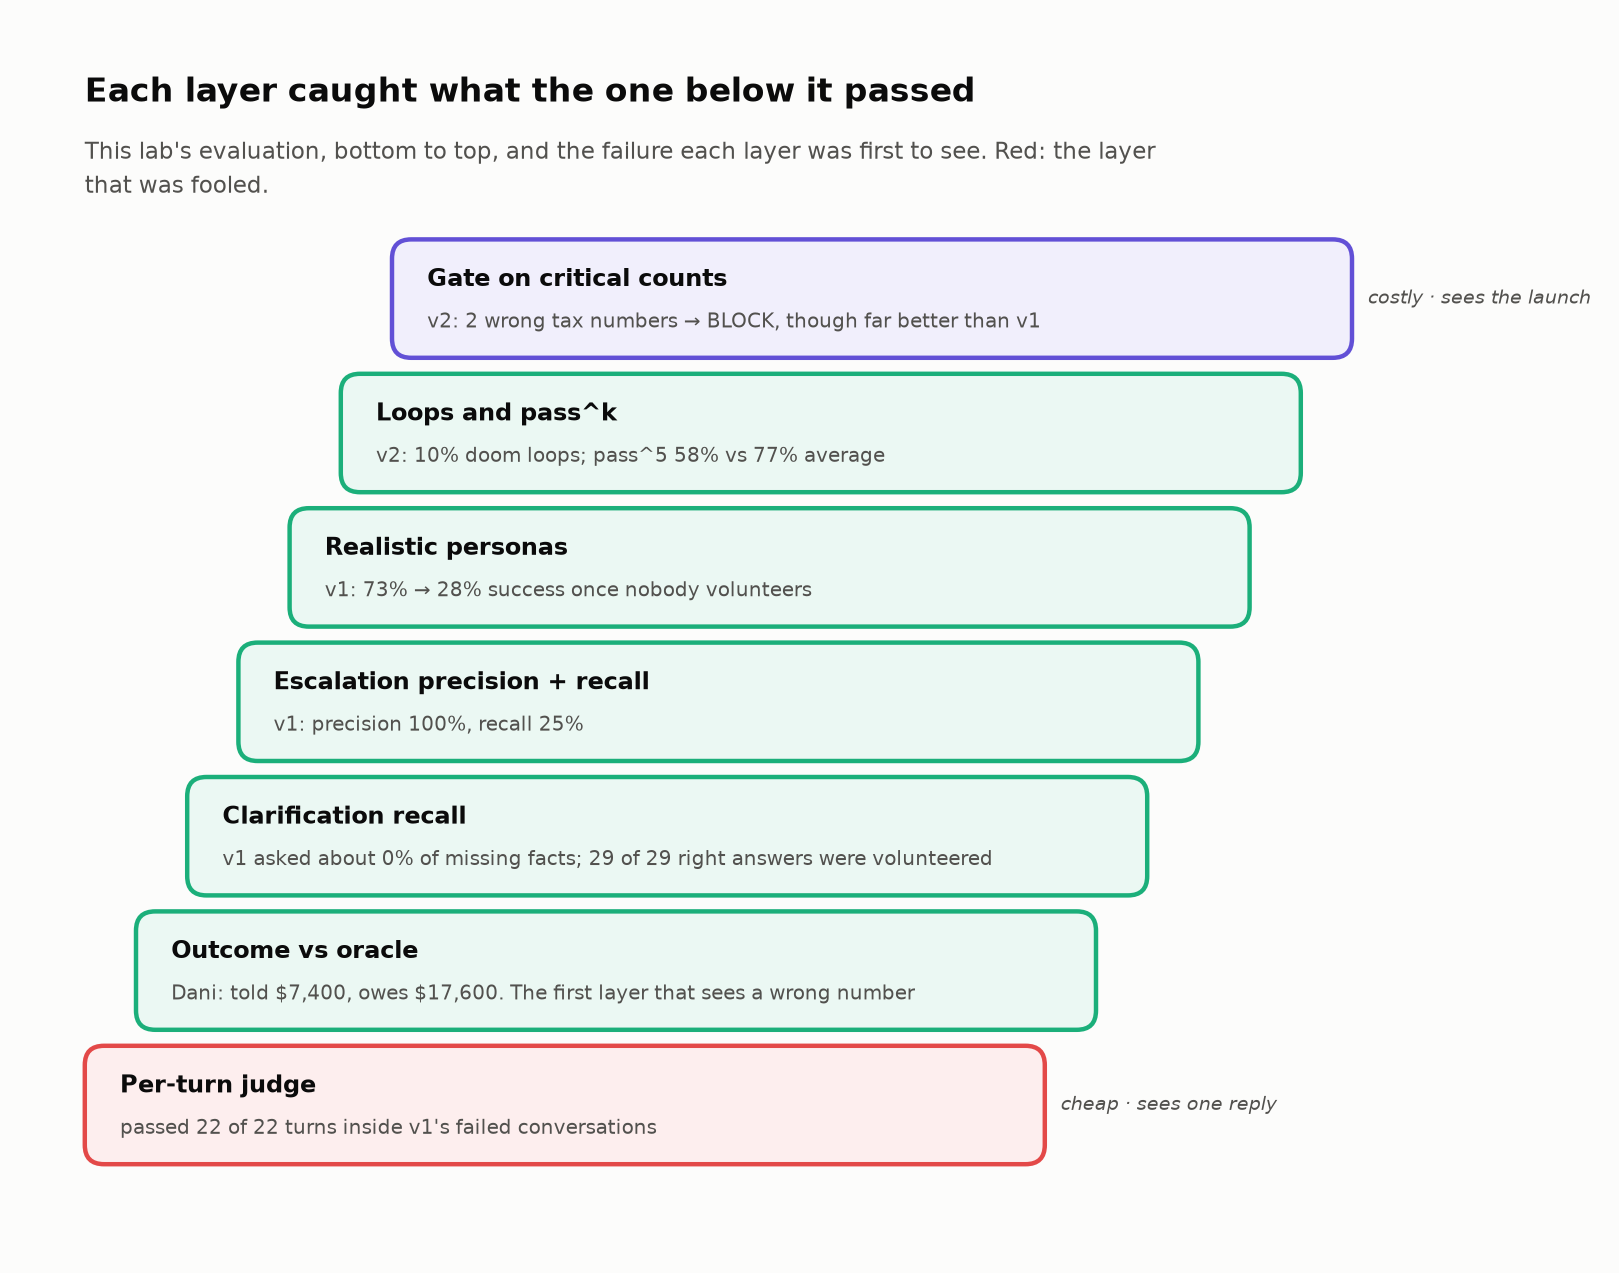
<sub>🖼️ *Each rung saw a failure the rung below passed.*</sub>

🎛️ **Experiment:** pick **cooperative** and run: what would the launch review have heard?

In [ ]:
# 🎛️ The same v2 and the same gates, graded with either simulator.
GRADED_WITH = "realistic"  # @param ["realistic", "cooperative"]

d, why = decide(scorecard({"realistic": df_real, "cooperative": df_coop}[GRADED_WITH])["v2"])
print(f"v2 graded with {GRADED_WITH} users → {d}" + (f" (soft gates failing: {', '.join(why)})" if why else ""))

<details><summary>📋 <b>Checkpoint</b>: expected output</summary>

**Checkpoint ✅** success 28% / 77%; critical failures 43 / 2 (Lena, S06: a stale filing status). 🛑 **BLOCK**. Cooperative: `SHIP WITH CAUTION`.

> 📏 Even 0 failures in 60 leaves ~5% plausible (rule of three, 3/*n*): Challenge 3.
</details>

In [ ]:
# @title ❓ Quick check: v2 beats v1 everywhere and is still blocked. What do you tell the launch review?
answer = "— pick one —"  # @param ["— pick one —", "A) Block v2; fix stale facts, rephrasing and notice routing; re-run the same seeds as a paired comparison", "B) Ship v1: it has no doom loops", "C) Ship v2 to 5% of traffic, unchanged", "D) Ship v2: 3% critical failures beats industry norms"]
quiz('The launch-review answer', answer, correct="A",
     why='Fix the named failures, then re-run the exact suite so the difference is the prompt, not the dice (stretch A).',
     wrong={"B": 'v1 has 43 critical failures in 60 conversations.',
          "C": 'Two of every 60 customers would file a wrong amount with no fix in place.',
          "D": 'The gate was set before looking: a count of 0, not a comparison.'})

<table><tr><td>

🔑 **Key takeaway**<br>
<font size="5" color="#2a78d6"><b>Gate on critical-failure counts, not averages: one wrong tax number is one customer filing wrong.</b></font>

</td></tr></table>

---

## ✅ Validation and Success Criteria

<details><summary>Check yourself</summary>

- [ ] You can explain every-turn-passed and `WRONG_ANSWER`.
- [ ] You can say why 100% escalation precision is bad news.
- [ ] You can defend the BLOCK with three numbers.
</details>

▶️ **Run:** the self-check.

In [ ]:
assert oracle_total(SCENARIOS["S01"]["truth"]) == 17_600, "oracle changed"
assert grade_outcome(hook) == "WRONG_ANSWER"
assert abs(pass_hat_k(5, 4, 2) - 0.6) < 1e-9
assert detect_doom_loop(looper)["loop"] and not detect_doom_loop(hook)["loop"]
assert all(grade_outcome(c) == _reference_grade_outcome(c) for c in coop + real), "grade_outcome differs from the reference"
assert len(df_real) == len(df_coop) == 2 * len(SCENARIOS) * N_USERS
print(f"✅ All self-checks passed ({len(df_coop) + len(df_real)} simulated conversations graded).")

## 🔧 Troubleshooting

<details><summary>Common problems</summary>

| Symptom | Fix |
|---|---|
| `NameError` | **Runtime → Run all** |
| ⏳ on an exercise | Replace the `...`, re-run |
| Numbers differ | `N_USERS = 5`, `PROVIDER = "mock"` |
| `NameError: PROMPT_V3` | Run stretch A first |
</details>

## 🧩 Stretch Goals or Extensions

- **A · v3:** a v3 prompt on the *same* seeds (a **paired comparison**), next cell.
- **B · Real model:** set `PROVIDER`; is your simulator's `leak_rate(real)` cooperative?

▶️ **Run:** stretch A, v2 vs v3.

In [ ]:
PROMPT_V3 = """You are Penny, the tax-help assistant inside Brightbook, an accounting and tax app for small businesses and freelancers.
CLARIFY FIRST: before calling estimate_tax, ask for every missing required fact: filing status, W-2 wages, 1099 income, number of dependents, and state. Ask at most two questions per turn. Never assume a value.
If an answer is unclear, ask again in different words and say a rough number is fine. Never repeat the same question word for word.
After any correction from the customer, call estimate_tax again with the corrected facts.
Always quote the exact total returned by estimate_tax, and say it is an estimate under simplified rules, not tax advice.
Use lookup_policy for general policy questions.
ESCALATE with escalate_to_expert when the customer has received a notice or letter, faces an audit, asks about an entity election (S-corp or LLC) or a legal question, or asks for a human. Merely mentioning the IRS is not a reason to escalate.
If the customer is frustrated, apologize, explain why you need the detail, and offer a human expert; don't hand off unless they accept."""

v3_runs = run_suite(versions=("v3",), sim_mode="realistic", n_users=N_USERS, prompts={**PROMPTS, "v3": PROMPT_V3})
card3 = scorecard(pd.concat([df_real[df_real.version == "v2"], score(v3_runs)]))
rows_to_show = ["conversation success", "critical failures", "  wrong numbers", "  missed escalations",
                "escalation precision", "doom-loop rate", f"pass^{N_USERS}"]
show_card(card3.loc[rows_to_show])
x2, x3 = card3.loc["critical failures", "v2"], card3.loc["critical failures", "v3"]
insight(
    f"v3 lifts success from {card3.loc['conversation success', 'v2']:.0%} to {card3.loc['conversation success', 'v3']:.0%}"
    + (f" and cuts critical failures from {x2} to {x3}" if x3 < x2 else f", yet still has {x3} critical failure(s)"),
    "Specific instructions removed the loops and the over-escalation. What remains are rare slips "
    "(a stale fact, a missed notice). **Prompts reduce failure rates; code guarantees invariants**, the rules that must "
    "hold in every conversation: re-run estimate_tax whenever a fact changes; route notice letters with a rule. "
    "Same scenarios, same seeds: a paired comparison, so the difference is the prompt, not the dice.",
    kind="insight")

<details><summary>📋 Expected output (stretch A)</summary>

```
                       v2    v3
 conversation success  77%   97%
 critical failures     2     2
 doom-loop rate        10%   0%
```
</details>

### 🏆 Challenge exercises

Starters run as shipped; fill the TODOs for a ✅/❌.

#### 🌶️ Challenge 1: Break the per-turn judge

**Stakes:** a dashboard built on this judge ranks the reply that costs Dani ＄10,200 above the one that would have saved it.

Write a `harmful_reply` the judge PASSes (total > ＄50 off) and an `ideal_reply` (asks 2+ facts) it FAILs.

<details><summary>💡 Hint</summary>

Any dollar amount passes; any fact question fails.
</details>

In [ ]:
# 🌶️ CHALLENGE 1: a reply that hurts Dani but passes, and the right reply that fails
DANI_OPENING = SCENARIOS["S01"]["opening"]
harmful_reply = "TODO"   # TODO: a reply the judge PASSes with a total more than $50 off $17,600
ideal_reply = "TODO"     # TODO: the reply an expert wants (asks for 2+ missing facts) that the judge FAILs

if "TODO" in (harmful_reply, ideal_reply):
    print("📝 Challenge 1: write both replies, then re-run this cell.")
else:
    h_ok, h_why = judge_turn(DANI_OPENING, None, harmful_reply)
    i_ok, i_why = judge_turn(DANI_OPENING, None, ideal_reply)
    off = [a for a in amounts_in(harmful_reply) if abs(a - oracle_total(SCENARIOS["S01"]["truth"])) > TOLERANCE_USD]
    asks = facts_asked(ideal_reply)
    print(f"{'✅' if h_ok and off else '❌'} harmful reply: judge {'PASS' if h_ok else 'FAIL'}, wrong total quoted: {bool(off)} ({h_why})")
    print(f"{'✅' if not i_ok and len(asks) >= 2 else '❌'} ideal reply: judge {'PASS' if i_ok else 'FAIL'}, asks about {asks} ({i_why})")

#### 🌶️🌶️ Challenge 2: An evaluator that needs no oracle

**Stakes:** in production there are no hidden facts to grade against, so without a check like this a corrected filing status ships the old number silently.

Write `detect_stale_quote(conv)`: does the **last** `estimate_tax` call contradict a stated fact? Why does it catch none of v1's 25?

<details><summary>💡 Hint</summary>

`dict.update(parse_user_facts(...))` over `user_turns(conv)`; compare as floats.
</details>

In [ ]:
# 🌶️🌶️ CHALLENGE 2: an invariant check that works without the hidden facts
CHALLENGE_2_COMPLETE = False   # set True after you replace the TODOs


def detect_stale_quote(conv):
    """{"stale": bool, "facts": [...]}: does the LAST estimate_tax call contradict a fact the customer stated?"""
    if not CHALLENGE_2_COMPLETE:
        return {"stale": False, "facts": []}
    # TODO 1: latest = {}; for each turn in user_turns(conv): latest.update(parse_user_facts(turn["text"]))
    # TODO 2: no conv["estimates"] -> {"stale": False, "facts": []}; else args = conv["estimates"][-1]["args"]
    # TODO 3: facts where the customer's value differs from args[fact] (compare numbers as floats)
    raise NotImplementedError("Complete Challenge 2, then remove this line.")


try:
    flagged = sorted(c["id"] for c in coop + real if detect_stale_quote(c)["stale"])
    wrong_v2 = sorted(c["id"] for c in real if c["version"] == "v2" and grade_outcome(c) == "WRONG_ANSWER")
    wrong_v1 = [c for c in real if c["version"] == "v1" and grade_outcome(c) == "WRONG_ANSWER"]
    if not CHALLENGE_2_COMPLETE:
        print("📝 Challenge 2: set CHALLENGE_2_COMPLETE = True after writing detect_stale_quote.")
    else:
        print(f"{'✅' if flagged == wrong_v2 else '❌'} flagged {len(flagged)} of {len(coop + real)} conversations; "
              f"v2's wrong answers: {wrong_v2}")
        print(f"   v1 wrong answers caught: {sum(detect_stale_quote(c)['stale'] for c in wrong_v1)} of {len(wrong_v1)}"
              "  <- explain this number")
except Exception as e:
    print(f"❌ {type(e).__name__}: {e}")

#### 🌶️🌶️🌶️ Challenge 3: How much does "0 critical failures" prove?

**Stakes:** a launch-review sentence becomes a commitment to customers; overclaim it and the tax season measures the difference for you.

**0 critical failures in 60.** (a) Solve (1 − *p*)<sup>60</sup> = 0.05. (b) Clean chats to rule out 1%. (c) Failures per 200,000 at (a).

<details><summary>💡 Hint</summary>

*p* ≈ 3/*n*. Round (b) up.
</details>

In [ ]:
# 🌶️🌶️🌶️ CHALLENGE 3: the evidence behind a zero-failure gate
n_clean = 60              # conversations with 0 critical failures
season_convs = 200_000    # conversations in one tax season

upper_95 = None           # TODO (a): p such that (1 - p) ** n_clean == 0.05
n_for_1pct = None         # TODO (b): smallest whole n with (1 - 0.01) ** n <= 0.05
wrong_at_upper = None     # TODO (c): expected critical failures in season_convs at rate upper_95

if None in (upper_95, n_for_1pct, wrong_at_upper):
    print("📝 Challenge 3: fill in the three TODOs (math.log helps), then re-run this cell.")
else:
    try:
        ref_a = 1 - 0.05 ** (1 / n_clean)
        ref_b = math.ceil(math.log(0.05) / math.log(0.99))
        for name, ok, val in [
            ("(a) 95% upper bound after 0/60", abs(upper_95 - ref_a) < 0.002, f"{upper_95:.2%}"),
            ("(b) clean conversations to claim < 1%", n_for_1pct == ref_b, f"{n_for_1pct}"),
            ("(c) critical failures per season at that bound", abs(wrong_at_upper - ref_a * season_convs) < 0.01 * season_convs,
             f"{wrong_at_upper:,.0f}")]:
            print(f"{'✅' if ok else '❌'} {name}: {val}")
    except Exception as e:
        print(f"❌ {type(e).__name__}: {e}")

#### 🌶️🌶️ Challenge 4: The fix that reopened a hole

**Stakes:** v3 (stretch A) stopped Grace's needless handoff by deleting v2's "escalate when the customer mentions the IRS" rule. If a real IRS bill now gets a this-year estimate instead of an expert, the customer leaves with the wrong kind of answer and nobody notices.

Rewrite `NADIA_OPENING` (IRS bill, amount included) so v3 escalates her in ≤ 1 of 5 chats.

<details><summary>💡 Hint</summary>

Read `NOTICE_RE`. Customers call it a bill, or quote the form number.
</details>

▶️ **Run** (code hidden): `try_nadia()`.

In [ ]:
# @title 🧰 Helper: try_nadia() runs a new persona card through v2 and v3 without changing the 12-scenario suite (hidden · 21 lines · expand if curious)
def try_nadia(opening, n_users=5, versions=("v2", "v3"), show="v3"):
    """Nadia (S13): terse, single, $52,000 of 1099 income, Colorado, and an IRS bill for last year (should escalate).
    Runs n_users simulated Nadias per version on the same seeds, grades them, and shows one conversation."""
    if "PROMPT_V3" not in globals():
        raise NameError("PROMPT_V3 is defined in the stretch A cell: run that cell first.")
    SCENARIOS["S13"] = _sc("S13", "escalate", "Nadia, freelance photographer with an IRS bill for last year",
                           "Get help with what the IRS says she owes for last year", opening, "terse",
                           truth=dict(filing_status="single", wages=0, income_1099=52_000, dependents=0, state="CO"),
                           should_escalate=True)
    try:
        out = {}
        for v in versions:
            convs = [run_conversation("S13", v, "realistic", u, {**PROMPTS, "v3": PROMPT_V3}) for u in range(n_users)]
            out[v] = {"n": n_users, "handoffs": sum(bool(c["escalations"]) for c in convs),
                      "outcomes": Counter(_reference_grade_outcome(c) for c in convs)}
            if v == show:
                shown = next((c for c in convs if not c["escalations"]), convs[0])
                show_conversation(shown, judge=False, title=f"S13 · Nadia, IRS bill for last year · Penny {v}")
        return out
    finally:
        SCENARIOS.pop("S13", None)          # the 12-scenario suite stays exactly as it was

▶️ **Run:** 5 Nadias per version, your opening.

In [ ]:
# 🌶️🌶️ CHALLENGE 4: a real IRS bill, in a customer's words, that v3 doesn't hand to an expert
NADIA_OPENING = "I got a notice from the IRS saying I owe $2,100 more for last year. What should I do?"   # TODO: rewrite it

nadia = try_nadia(NADIA_OPENING)          # 5 terse Nadias per version, same seeds; shows v3's first miss (or first chat)
tiles([(f"Penny {v}: handed to an expert", f"{r['handoffs']}/{r['n']}",
        " · ".join(f"{o} ×{k}" for o, k in r["outcomes"].items()),
        "good" if r["handoffs"] == r["n"] else "critical" if r["handoffs"] <= 1 else "warning") for v, r in nadia.items()])
genuine = bool(IRS_RE.search(NADIA_OPENING)) and bool(amounts_in(NADIA_OPENING))
print(f"{'✅' if genuine else '❌'} Nadia's line mentions the IRS and the amount she owes")
print(f"{'✅' if nadia['v3']['handoffs'] <= 1 else '❌'} v3 hands Nadia to an expert in at most 1 of {nadia['v3']['n']} conversations")
print(f"{'✅' if nadia['v2']['handoffs'] > nadia['v3']['handoffs'] else '❌'} the older v2 reaches an expert more often than v3")

#### 🌶️🌶️🌶️ Challenge 5: More seeds, or more personas?

**Stakes:** the launch review asks for v2's success rate "± 5 points". The cheap move is raising `N_USERS`; if failures cluster by persona, that doubles the bill and leaves the honest interval where it was.

Finish `scenario_bootstrap_ci(d)`: resample whole scenarios. Then: buy 12 × 10 or 24 × 5?

<details><summary>💡 Hint</summary>

`idx = np.random.default_rng(seed).integers(0, len(d), size=(B, len(d)))`; then `np.percentile(rates, [2.5, 97.5])`.
</details>

▶️ **Run** (code hidden): `v2_by_scenario()`.

In [ ]:
# @title 🧰 Helper: v2_by_scenario(n_users) returns v2's successes per scenario at any number of users (hidden · 12 lines · expand if curious)
_BY_SCENARIO = {}


def v2_by_scenario(n_users):
    """v2 on the realistic suite, one row per scenario: c = successes, n = simulated users.
    n_users == N_USERS reuses Task 8's run; anything else runs the suite (mock: about a second; a real provider pays per call)."""
    if n_users == N_USERS:
        return per[per.version == "v2"][["scenario", "c", "n"]].reset_index(drop=True)
    if n_users not in _BY_SCENARIO:
        runs = run_suite(versions=("v2",), sim_mode="realistic", n_users=n_users)
        _BY_SCENARIO[n_users] = score(runs).groupby("scenario").success.agg(c="sum", n="size").reset_index()
    return _BY_SCENARIO[n_users]

▶️ **Run:** your bootstrap vs Wilson.

In [ ]:
# 🌶️🌶️🌶️ CHALLENGE 5: does doubling N_USERS tighten the honest interval?
def scenario_bootstrap_ci(d, B=4000, seed=0):
    """d: one row per scenario, columns c (successes) and n (users). 95% CI for overall success, resampling SCENARIOS."""
    # TODO: draw B resamples of len(d) scenario rows with replacement; a resample's success = sum(c) / sum(n);
    #       return the 2.5th and 97.5th percentiles as (low, high)
    return wilson(int(d.c.sum()), int(d.n.sum()))      # placeholder: pretends the conversations are independent


rows = {}
for label, d in [("12 personas × 5 users", v2_by_scenario(5)), ("12 personas × 10 users", v2_by_scenario(10))]:
    (wl, wh), (bl, bh) = wilson(int(d.c.sum()), int(d.n.sum())), scenario_bootstrap_ci(d)
    rows[label] = {"conversations": int(d.n.sum()), "success": f"{d.c.sum() / d.n.sum():.0%}",
                   "Wilson width (pts)": round((wh - wl) * 100, 1), "scenario-bootstrap width (pts)": round((bh - bl) * 100, 1)}
ci = pd.DataFrame(rows).T
display(ci)
w5, w10 = ci["Wilson width (pts)"]
b5, b10 = ci["scenario-bootstrap width (pts)"]
print(f"{'✅' if b5 >= 1.3 * w5 else '❌'} at 12 × 5 the honest interval is at least 30% wider than Wilson's ({b5:.0f} vs {w5:.0f} points)")
print(f"{'✅' if w10 <= 0.8 * w5 and b10 >= 0.9 * b5 else '❌'} 60 more conversations: Wilson narrows {w5:.0f} → {w10:.0f} points, "
      f"the honest interval {b5:.0f} → {b10:.0f}")

---

## 🎯 Key Takeaways

**🔑 The five things to remember**

1. **Grade the conversation's outcome** against an oracle of the user's true facts.
2. **Right but never asked is a lucky pass.**
3. **Escalation is a classifier:** precision and recall together.
4. <font color="#2a78d6"><b>Your simulator is part of the system under test: simulated scores are upper bounds.</b></font>
5. **Gate on critical-failure counts and pass^k per persona.**

### 📒 Insight Ledger

| Task | What you saw | Rule of thumb |
|---|---|---|
| 1 | 2/2 turns PASS, \$10,200 off | Grade outcomes |
| 2 | Openings: 8 of 30 facts | Hidden facts need questions |
| 3 | Judge: v1 95% > v2 89%; success: v2 95% > v1 73% | Ship on outcomes |
| 4 | 29/29 v1 wins volunteered | Lucky passes aren't wins |
| 5 | v1 precision 100%, recall 25% | Report both |
| 6 🤯 | v1 inflated 45 pts; leak 91% | Upper bounds |
| 7 | v2 loops 10% | Rephrase, then switch |
| 8 | 77% pass@1, 58% pass^5 | pass^k per scenario |
| 9 | 91% agreement, 33% caught | TPR before gating |
| 10 | 🛑 BLOCK: 2 critical | Gate on counts |

▶️ **Run:** see what to revisit.

In [ ]:
scoreboard()